# Phase 2 · Phân tích thống kê Q1–Q5 & Tổng hợp
**Nhóm CSC17104:** Trần Nhật Dương (Q1–Q2) · Nguyễn Mạnh Hà (Q3–Q4) · Hoàng Công Lý (Q5)

Notebook trả lời 5 câu hỏi phân tích thống kê (non-ML); câu Q6 (Machine Learning) nằm ở `03_ml_question.ipynb`. Mỗi câu trình bày theo đúng khung của đề: **Câu hỏi → Lợi ích khi trả lời được → Tiền xử lý (mô tả + code) → Phân tích (mô tả + code) → Kết quả & kết luận**, kèm điểm bất ngờ, ứng dụng có điều kiện và hạn chế.

**Quy ước chung** (hàm trong `coupon_project.stats`): tỷ lệ chấp nhận = trung bình của `Y` theo `%`; chênh lệch giữa hai nhóm tính bằng **điểm phần trăm (pp)**; khoảng tin cậy 95% (Wilson hoặc bootstrap cho một tỷ lệ — ghi rõ ở từng bảng/hình; bootstrap cho chênh lệch); nhóm có `n < 30` được gắn cờ `small_n`/`*`; chỉ kết luận **mối liên hệ trong khảo sát**, không kết luận nhân quả. Trong 6 tiêu chí độ sâu D1–D6 của đề, nhóm thể hiện **D2, D3, D4, D5, D6** (5/6).

**Mục lục:** Danh sách câu hỏi · Phase 2.1 (Q1, Q2) · Phase 2.2 (Q3, Q4) · Phase 2.3 (Q5) · Phase 2.4 Tổng hợp, hạn chế & hướng phát triển · Reflection · Tài liệu tham khảo

## Danh sách câu hỏi nghiên cứu (Asking meaningful questions)

| Câu | Owner | Câu hỏi | Lợi ích khi trả lời được (ai dùng, quyết định gì) | Tiêu chí |
| --- | --- | --- | --- | --- |
| **Q1** | Dương | Khoảng cách và hướng di chuyển đến điểm dùng coupon liên hệ thế nào với tỷ lệ chấp nhận sau khi phân tầng theo mục đích chuyến đi và loại coupon? | Ứng dụng dẫn đường/quán đối tác chọn **bán kính và hướng** hiển thị coupon, tránh gợi ý bắt tài xế đi vòng xa. | D3, D4, D5 |
| **Q2** | Dương | Chênh lệch chấp nhận giữa hạn `1d` và `2h` thay đổi ra sao theo khung giờ trong ngày và loại coupon? | Đội marketing chọn phát ưu đãi **ngắn hạn hay linh hoạt** theo giờ và loại dịch vụ. | D2, D4, D5 |
| **Q3** | Hà | Trong cùng loại coupon, người có thói quen ghé địa điểm tương ứng thường xuyên hơn có tỷ lệ chấp nhận cao hơn không? | Cơ sở để **cá nhân hóa** ưu đãi theo thói quen thay vì gửi đại trà. | D3, D4, D5, D6 |
| **Q4** | Hà | Người đồng hành (`passanger`) liên hệ ra sao với tỷ lệ chấp nhận sau khi kiểm soát loại coupon và mục đích hành trình (`destination`)? | Biết có nên dùng tín hiệu "ai đang ngồi trên xe" khi gợi ý, hay khác biệt chỉ do bối cảnh chuyến đi. | D4, D5 |
| **Q5** | Lý | Khác biệt tỷ lệ chấp nhận theo nhóm tuổi và khoảng thu nhập còn giữ lại bao nhiêu sau khi chuẩn hóa theo loại coupon và thói quen tương ứng? | Đội marketing biết **phân khúc nhân khẩu học** còn giá trị hay không khi đã biết thói quen. | D4, D5, D6 |
| **Q6** | Lý | Các đặc trưng biết trước thời điểm hiển thị coupon dự đoán ý định `Y` vượt baseline ở mức nào khi tách dữ liệu theo người trả lời? *(`03_ml_question.ipynb`)* | Hệ thống gợi ý **xếp hạng** nên gửi coupon nào cho ai trước khi hiển thị. | ML |

Các câu đều cần nhiều bước (tạo biến, phân tầng, chuẩn hóa, ước lượng bất định, kiểm tra độ bền) chứ không trả lời được bằng một dòng `groupby`.

In [1]:
import sys
from pathlib import Path

# Cho phép import gói coupon_project trong src/ dù mở notebook từ thư mục gốc hay notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coupon_project.data import RAW_CSV_PATH, load_raw_data, row_count_log, save_table
from coupon_project.features import (
    AGE_ORDER, COUPON_FREQUENCY, COUPONS, DESTINATIONS, EXPIRATION_ORDER, FREQUENCIES,
    INCOME_ORDER, PASSENGERS, TIME_ORDER, TRAVEL_BAND_ORDER, add_travel_time_band,
    build_respondent_id, check_journey_flags, matched_frequency,
)
from coupon_project.plotting import plot_bars_ci, plot_heatmap, save_figure, set_style
from coupon_project.stats import (
    MIN_N, cluster_diff_ci, cluster_rates_ci, contrasts,
    pivot_expiration, rate_table, standardized_contrast,
)

df = load_raw_data(RAW_CSV_PATH)  # mỗi Phase đọc lại dữ liệu gốc, không phụ thuộc notebook khác
print(row_count_log(len(df), len(df), "Phase 2 raw load (no rows dropped)"))

Phase 2 raw load (no rows dropped): 12,684 -> 12,684 rows (delta +0)


---
## Phase 2.1 · Bối cảnh hành trình & Thời hạn coupon *(Trần Nhật Dương — Q1 & Q2)*

### Q1 · Khoảng cách & hướng di chuyển (`D3, D4, D5`)
- **Câu hỏi:** Khoảng cách và hướng di chuyển đến điểm dùng coupon liên hệ thế nào với tỷ lệ chấp nhận sau khi phân tầng theo mục đích chuyến đi và loại coupon?
- **Lợi ích khi trả lời được:** giúp ứng dụng dẫn đường (và quán đối tác) chọn **bán kính** và **hướng** hiển thị coupon — nếu quán xa hoặc ngược hướng làm tỷ lệ nhận giảm mạnh ở loại quán nào thì không nên gợi ý quán đó khi tài xế phải đi vòng.

#### Tiền xử lý
1. Không bỏ dòng nào (`12.684` dòng); kiểm tra lại logic cờ khoảng cách (`GEQ25 ⇒ GEQ15 ⇒ GEQ5`) và cờ hướng (`direction_same + direction_opp = 1`).
2. **Tạo biến mới `travel_time_band` (D3)** từ 2 cờ nhị phân: `GEQ15 = 0` → `5-<15 min`; `GEQ15 = 1, GEQ25 = 0` → `15-<25 min`; `GEQ25 = 1` → `>=25 min`. Đây là **ngưỡng** thời gian lái do khảo sát đặt ra, không phải số phút đo được; mức thấp nhất bắt đầu từ 5 phút vì `GEQ5` luôn bằng 1.
3. Dùng trực tiếp `direction_same` (`1` = quán cùng hướng với điểm đến).
4. Bản kiểm tra độ bền: bỏ `74` dòng trùng hoàn toàn rồi tính lại.

In [2]:
q1_df = add_travel_time_band(df)  # bản sao có thêm cột travel_time_band (Categorical có thứ tự)
print("Kiểm tra cờ:", check_journey_flags(q1_df))
band_counts = q1_df["travel_time_band"].value_counts().reindex(TRAVEL_BAND_ORDER)
print("Số dòng mỗi mức:", band_counts.to_dict())

Kiểm tra cờ: {'n_rows': 12684, 'geq5_always_one': True, 'invalid_geq_hierarchy_count': 0, 'direction_complement_ok': True}
Số dòng mỗi mức: {'5-<15 min': 5562, '15-<25 min': 5611, '>=25 min': 1511}


#### Phân tích
1. Tỷ lệ chấp nhận theo từng mức `travel_time_band`, kèm 95% bootstrap CI.
2. Chênh lệch **gần − xa** (`5-<15 min` − `>=25 min`) trên toàn mẫu, rồi **trong từng `destination`** và **trong từng `coupon`** (D4: so sánh trong cùng tầng để tách ảnh hưởng của mục đích chuyến đi và loại quán).
3. Chênh lệch **cùng hướng − ngược hướng** trên toàn mẫu, trong từng `destination` và trong từng ô `destination × travel_time_band`.
4. Mọi chênh lệch kèm 95% bootstrap CI (D5); tầng thiếu một trong hai nhóm được đánh dấu `no_common_support` thay vì điền số.

In [3]:
display(rate_table(q1_df, ["travel_time_band"], ci_method="bootstrap"))

# Gần (5-<15 min) − xa (>=25 min): toàn mẫu, trong từng destination, trong từng coupon
NEAR, FAR = "5-<15 min", ">=25 min"
dist_tables = {
    "overall": contrasts(q1_df, [], "travel_time_band", NEAR, FAR, key="q1_overall"),
    "destination": contrasts(q1_df, ["destination"], "travel_time_band", NEAR, FAR,
                             key="q1_dest"),
    "coupon": contrasts(q1_df, ["coupon"], "travel_time_band", NEAR, FAR, key="q1_coupon"),
}
# Cùng hướng (1) − ngược hướng (0): toàn mẫu, theo destination, theo destination × thời gian
dir_tables = {
    "overall": contrasts(q1_df, [], "direction_same", 1, 0, key="q1_dir_overall"),
    "destination": contrasts(q1_df, ["destination"], "direction_same", 1, 0,
                             key="q1_dir_dest"),
    "destination_band": contrasts(q1_df, ["destination", "travel_time_band"],
                                  "direction_same", 1, 0, key="q1_dir_strata"),
}
for table in [*dist_tables.values(), *dir_tables.values()]:
    display(table)
dist_all = pd.concat([t.assign(scope=s) for s, t in dist_tables.items()], ignore_index=True)
dir_all = pd.concat([t.assign(scope=s) for s, t in dir_tables.items()], ignore_index=True)
save_table(dist_all, "q1_distance_contrasts")
save_table(dir_all, "q1_direction_contrasts")

# Độ bền: bỏ các dòng trùng hoàn toàn rồi tính lại chênh gần − xa
df_dedup = add_travel_time_band(df.drop_duplicates())
print(row_count_log(len(df), len(df_dedup), "Sensitivity drop exact duplicates"))
display(contrasts(df_dedup, [], "travel_time_band", NEAR, FAR, key="q1_dedup"))

,travel_time_band,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_n
0,5-<15 min,5562,3416,61.42,60.09,62.68,False
1,15-<25 min,5611,3146,56.07,54.75,57.41,False
2,>=25 min,1511,648,42.89,40.24,45.34,False


,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,5-<15 min,>=25 min,3416,648,5562,1511,61.42,42.89,18.53,15.69,21.38,False,ok


,destination,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,Home,5-<15 min,>=25 min,990,185,1792,472,55.25,39.19,16.05,11.20,21.21,False,ok
1,No Urgent Place,5-<15 min,>=25 min,1694,0,2639,0,64.19,NaN,NaN,NaN,NaN,True,no_common_support
2,Work,5-<15 min,>=25 min,732,463,1131,1039,64.72,44.56,20.16,16.13,24.28,False,ok


,coupon,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,Bar,5-<15 min,>=25 min,299,197,679,510,44.04,38.63,5.41,-0.28,11.19,False,ok
1,Carry out & Take away,5-<15 min,>=25 min,657,194,873,265,75.26,73.21,2.05,-3.75,8.27,False,ok
2,Coffee House,5-<15 min,>=25 min,1054,107,1923,310,54.81,34.52,20.29,14.51,26.11,False,ok
3,Restaurant(20-50),5-<15 min,>=25 min,246,49,547,116,44.97,42.24,2.73,-7.14,12.71,False,ok
4,Restaurant(<20),5-<15 min,>=25 min,1160,101,1540,310,75.32,32.58,42.74,37.13,48.56,False,ok


,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,1,0,1586,5624,2724,9960,58.22,56.47,1.76,-0.33,3.85,False,ok


,destination,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,Home,1,0,912,727,1524,1713,59.84,42.44,17.40,13.85,20.93,False,ok
1,No Urgent Place,1,0,0,3982,0,6283,NaN,63.38,NaN,NaN,NaN,True,no_common_support
2,Work,1,0,674,915,1200,1964,56.17,46.59,9.58,6.26,13.21,False,ok


,destination,travel_time_band,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,Home,5-<15 min,1,0,692,298,1179,613,58.69,48.61,10.08,5.09,15.03,False,ok
1,Home,15-<25 min,1,0,220,244,345,628,63.77,38.85,24.91,18.47,30.81,False,ok
2,Home,>=25 min,1,0,0,185,0,472,NaN,39.19,NaN,NaN,NaN,True,no_common_support
3,No Urgent Place,5-<15 min,1,0,0,1694,0,2639,NaN,64.19,NaN,NaN,NaN,True,no_common_support
4,No Urgent Place,15-<25 min,1,0,0,2288,0,3644,NaN,62.79,NaN,NaN,NaN,True,no_common_support
5,Work,5-<15 min,1,0,496,236,800,331,62.00,71.30,-9.30,-14.51,-3.44,False,ok
6,Work,15-<25 min,1,0,178,216,400,594,44.50,36.36,8.14,1.88,14.14,False,ok
7,Work,>=25 min,1,0,0,463,0,1039,NaN,44.56,NaN,NaN,NaN,True,no_common_support


Sensitivity drop exact duplicates: 12,684 -> 12,610 rows (delta -74)


,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,5-<15 min,>=25 min,3407,614,5551,1463,61.38,41.97,19.41,16.56,22.29,False,ok


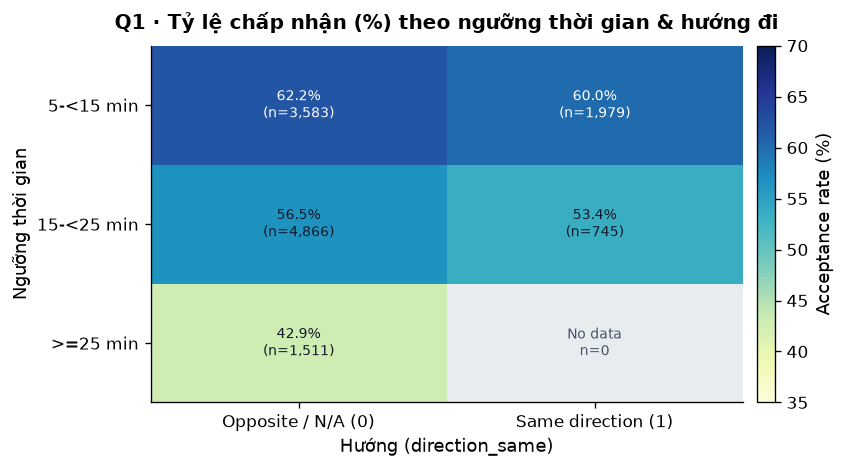

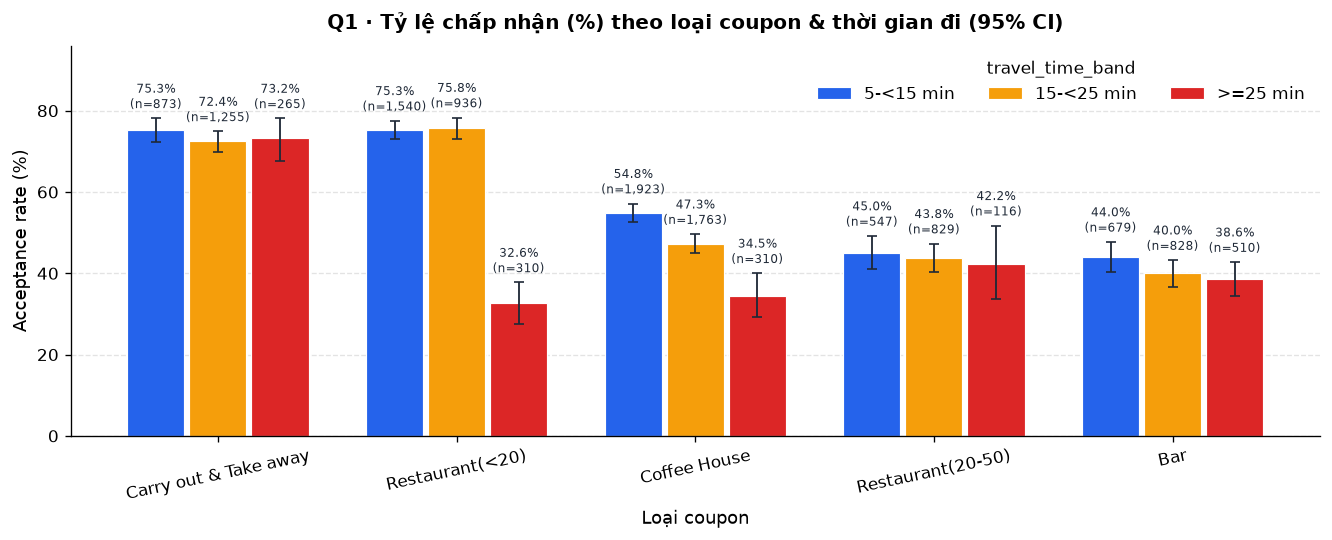

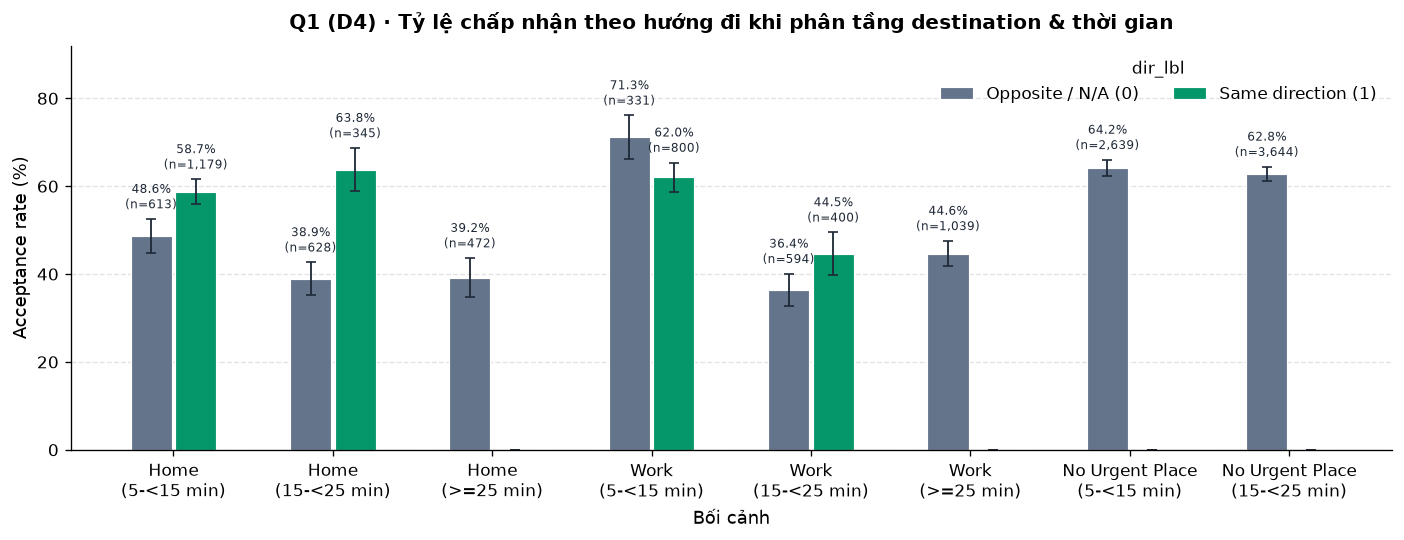

In [4]:
col_map = {0: "Opposite / N/A (0)", 1: "Same direction (1)"}
hm_args = dict(values="Y", index="travel_time_band", columns="direction_same", observed=False)
q1_hm_rate = q1_df.pivot_table(aggfunc="mean", **hm_args).mul(100).rename(columns=col_map)
q1_hm_cnt = (q1_df.pivot_table(aggfunc="count", **hm_args)
             .fillna(0).astype(int).rename(columns=col_map))
plot_heatmap(
    q1_hm_rate, q1_hm_cnt,
    "Q1 · Tỷ lệ chấp nhận (%) theo ngưỡng thời gian & hướng đi",
    "Hướng (direction_same)", "Ngưỡng thời gian", "Acceptance rate (%)",
    out_name="q1_fig1_heatmap_travel_time_direction", vmin=35, vmax=70, figsize=(7.4, 4.0),
)
plt.show()

coupon_ord_q1 = ["Carry out & Take away", "Restaurant(<20)", "Coffee House",
                 "Restaurant(20-50)", "Bar"]
plot_bars_ci(
    rate_table(q1_df, ["coupon", "travel_time_band"], ci_method="bootstrap"),
    "coupon", "travel_time_band", coupon_ord_q1, TRAVEL_BAND_ORDER,
    "Q1 · Tỷ lệ chấp nhận (%) theo loại coupon & thời gian đi (95% CI)", "Loại coupon",
    out_name="q1_fig2_grouped_bar_coupon_travel_time",
    colors=["#2563EB", "#F59E0B", "#DC2626"], figsize=(11.2, 4.6), ylim=(0, 96),
    rotate_xticks=12,
)
plt.show()

q1_dd = rate_table(q1_df, ["destination", "travel_time_band", "direction_same"],
                   ci_method="bootstrap")
q1_dd["stratum"] = (q1_dd["destination"].astype(str) + "\n("
                    + q1_dd["travel_time_band"].astype(str) + ")")
q1_dd["dir_lbl"] = q1_dd["direction_same"].map(col_map)
stratum_ord = [
    "Home\n(5-<15 min)", "Home\n(15-<25 min)", "Home\n(>=25 min)",
    "Work\n(5-<15 min)", "Work\n(15-<25 min)", "Work\n(>=25 min)",
    "No Urgent Place\n(5-<15 min)", "No Urgent Place\n(15-<25 min)",
]
plot_bars_ci(
    q1_dd, "stratum", "dir_lbl", stratum_ord, ["Opposite / N/A (0)", "Same direction (1)"],
    "Q1 (D4) · Tỷ lệ chấp nhận theo hướng đi khi phân tầng destination & thời gian",
    "Bối cảnh", out_name="q1_fig3_stratified_destination_direction",
    colors=["#64748B", "#059669"], figsize=(11.8, 4.6), ylim=(0, 92),
)
plt.show()

#### Kết quả & kết luận Q1
- **Trả lời trực tiếp:** càng xa thì tỷ lệ chấp nhận càng thấp: `5-<15 min` **61,42%** (`n = 5.562`) > `15-<25 min` **56,07%** (`n = 5.611`) > `>=25 min` **42,89%** (`n = 1.511`); chênh gần − xa **+18,53 pp** (95% CI `[15,69; 21,38]`), bỏ 74 dòng trùng vẫn là **+19,41 pp**.
- **Sau khi phân tầng (D4):** chiều "gần cao hơn xa" giữ nguyên trong `Home` (**+16,05 pp**) và `Work` (**+20,16 pp**) nhưng **độ lớn khác hẳn theo loại quán**: `Restaurant(<20)` giảm **42,74 pp** (75,32% → 32,58%), `Coffee House` giảm **20,29 pp**, trong khi `Carry out & Take away` gần như không đổi (75,26% → 73,21%, chênh +2,05 pp, CI chứa 0).
- **Hướng đi bị điểm đến che khuất:** gộp thô, cùng hướng chỉ cao hơn **+1,76 pp** (CI `[−0,33; 3,85]`, chứa 0) vì toàn bộ `6.283` dòng `No Urgent Place` đều có `direction_same = 0`. Khi cố định `Home`, cùng hướng cao hơn **+17,40 pp** (riêng `15-<25 min`: **+24,91 pp**); trong `Work` là **+9,58 pp**, nhưng riêng ô `Work` × `5-<15 min` lại **đảo chiều** (**−9,30 pp**).
- **Điểm bất ngờ:** `Carry out & Take away` gần như không nhạy với khoảng cách, còn nhà hàng bình dân `Restaurant(<20)` lại nhạy nhất — có thể vì đồ mang đi dễ mua tiện đường, còn ăn tại nhà hàng tốn thêm thời gian.
- **Ứng dụng có điều kiện:** với nhà hàng/quán cà phê nên ưu tiên quán trong ngưỡng `< 25 phút` và cùng hướng điểm đến; với đồ ăn mang đi có thể nới bán kính. Đây là gợi ý để thử nghiệm (A/B test) vì dữ liệu chỉ đo ý định trong khảo sát.
- **Hạn chế:** cờ `GEQ` là ngưỡng rời rạc (không phải GPS); có ô rỗng cấu trúc (`No Urgent Place` không có `>=25 min` hay `direction_same = 1`; mọi tình huống `>=25 min` đều ngược hướng); CI bootstrap theo dòng chưa tính việc một người trả lời nhiều tình huống (Q5 cho thấy CI như vậy hẹp hơn thực tế).

### Q2 · Thời hạn `2h` vs `1d` theo khung giờ trong ngày & loại coupon (`D2, D4, D5`)
- **Câu hỏi:** Chênh lệch chấp nhận giữa hạn `1d` và `2h` thay đổi ra sao theo khung giờ trong ngày và loại coupon?
- **Lợi ích khi trả lời được:** đội marketing quyết định phát ưu đãi **ngắn hạn (`2h`) hay linh hoạt (`1d`)** cho từng khung giờ và loại dịch vụ, thay vì một quy tắc chung cho mọi trường hợp.

#### Tiền xử lý
1. Không bỏ dòng nào. `time` chỉ là **5 mốc giờ trong một ngày** (không có ngày tháng) nên **không** xử lý như chuỗi thời gian; `time` và `expiration` được chuyển sang biến phân loại có thứ tự (`TIME_ORDER`, `EXPIRATION_ORDER`) để bảng và biểu đồ đúng thứ tự.
2. **Định dạng lại dữ liệu (D2):** `pivot_table` (hàng = `time`, cột = `expiration`, giá trị = tỷ lệ `Y` và số dòng `n`) rồi `melt` về dạng dài để vẽ biểu đồ — gói trong hàm `stats.pivot_expiration`.

In [5]:
q2_rate_p, q2_cnt_p, q2_long = pivot_expiration(df)  # pivot tỷ lệ, pivot n, bảng dài (melt)
save_table(q2_long, "q2_time_expiration_pivot")
display(q2_rate_p)
display(q2_cnt_p)
display(q2_long.head(4))

expiration,2h,1d,diff_1d_minus_2h_pp
time,,,
7AM,37.51,58.29,20.78
10AM,61.76,59.75,-2.01
2PM,55.85,71.77,15.92
6PM,54.53,61.82,7.29
10PM,36.90,63.03,26.13


expiration,2h,1d
time,,
7AM,1229,1935
10AM,1229,1046
2PM,709,1300
6PM,1491,1739
10PM,935,1071


,time,expiration,rate_pct,n
0,7AM,2h,37.51,1229
1,10AM,2h,61.76,1229
2,2PM,2h,55.85,709
3,6PM,2h,54.53,1491


#### Phân tích
1. Chênh lệch `1d − 2h` (pp, 95% bootstrap CI) trên toàn mẫu, trong từng khung giờ và trong từng loại coupon.
2. **Kiểm soát loại coupon (D4):** tính lại chênh lệch trong từng ô `time × coupon`; dùng cơ cấu loại coupon của nhóm `1d` và `2h` lúc `10AM` để giải thích vì sao bảng gộp thô đổi chiều (nghịch lý Simpson).
3. Liệt kê riêng các ô của `Bar` (có ô rỗng và có ô đảo chiều) để kết luận kèm CI.

In [6]:
# 1d − 2h: toàn mẫu, theo giờ, theo coupon (lưu bảng) và theo giờ × coupon (dùng cho hình)
q2_tables = {
    "overall": contrasts(df, [], "expiration", "1d", "2h", key="q2_overall"),
    "time": contrasts(df, ["time"], "expiration", "1d", "2h", key="q2_time"),
    "coupon": contrasts(df, ["coupon"], "expiration", "1d", "2h", key="q2_coupon"),
}
q2_tc_diff = contrasts(df, ["time", "coupon"], "expiration", "1d", "2h", key="q2_tc")
for table in q2_tables.values():
    display(table)
q2_all = pd.concat([t.assign(scope=s) for s, t in q2_tables.items()], ignore_index=True)
save_table(q2_all, "q2_expiry_contrasts")

print("Giải thích nghịch lý lúc 10AM (cơ cấu % coupon trong 1d vs 2h):")
at_10am = df[df["time"] == "10AM"]
coupon_mix = pd.crosstab(at_10am["coupon"], at_10am["expiration"], normalize="columns")
display(coupon_mix.mul(100).round(1))
display(q2_tc_diff[q2_tc_diff["time"] == "10AM"])

print("Riêng coupon Bar ở từng khung giờ (ô thiếu 2h có status = no_common_support):")
display(q2_tc_diff[q2_tc_diff["coupon"] == "Bar"])

,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,1d,2h,4436,2774,7091,5593,62.56,49.6,12.96,11.27,14.7,False,ok


,time,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,10AM,1d,2h,625,759,1046,1229,59.75,61.76,-2.01,-5.78,2.24,False,ok
1,10PM,1d,2h,675,345,1071,935,63.03,36.90,26.13,22.03,30.32,False,ok
2,2PM,1d,2h,933,396,1300,709,71.77,55.85,15.92,11.52,20.20,False,ok
3,6PM,1d,2h,1075,813,1739,1491,61.82,54.53,7.29,3.85,10.67,False,ok
4,7AM,1d,2h,1128,461,1935,1229,58.29,37.51,20.78,17.11,24.25,False,ok


,coupon,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,Bar,1d,2h,641,186,1556,461,41.20,40.35,0.85,-4.30,5.73,False,ok
1,Carry out & Take away,1d,2h,1138,622,1456,937,78.16,66.38,11.78,8.21,15.48,False,ok
2,Coffee House,1d,2h,1033,962,1769,2227,58.39,43.20,15.20,12.03,18.19,False,ok
3,Restaurant(20-50),1d,2h,498,160,956,536,52.09,29.85,22.24,17.46,27.50,False,ok
4,Restaurant(<20),1d,2h,1126,844,1354,1432,83.16,58.94,24.22,20.96,27.40,False,ok


Giải thích nghịch lý lúc 10AM (cơ cấu % coupon trong 1d vs 2h):


expiration,1d,2h
coupon,,
Bar,36.1,5.4
Carry out & Take away,14.2,29.9
Coffee House,32.2,45.7
Restaurant(20-50),6.7,3.4
Restaurant(<20),10.7,15.5


,time,coupon,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,10AM,Bar,1d,2h,150,11,378,66,39.68,16.67,23.02,12.79,32.78,False,ok
1,10AM,Carry out & Take away,1d,2h,118,245,149,368,79.19,66.58,12.62,4.26,20.58,False,ok
2,10AM,Coffee House,1d,2h,221,355,337,562,65.58,63.17,2.41,-3.82,8.70,False,ok
3,10AM,Restaurant(20-50),1d,2h,48,21,70,42,68.57,50.00,18.57,0.46,36.19,False,ok
4,10AM,Restaurant(<20),1d,2h,88,127,112,191,78.57,66.49,12.08,1.95,21.84,False,ok


Riêng coupon Bar ở từng khung giờ (ô thiếu 2h có status = no_common_support):


,time,coupon,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,10AM,Bar,1d,2h,150,11,378,66,39.68,16.67,23.02,12.79,32.78,False,ok
5,10PM,Bar,1d,2h,84,100,203,199,41.38,50.25,-8.87,-18.37,0.14,False,ok
10,2PM,Bar,1d,2h,40,0,118,0,33.90,NaN,NaN,NaN,NaN,True,no_common_support
15,6PM,Bar,1d,2h,189,75,370,196,51.08,38.27,12.82,4.32,21.28,False,ok
20,7AM,Bar,1d,2h,178,0,487,0,36.55,NaN,NaN,NaN,NaN,True,no_common_support


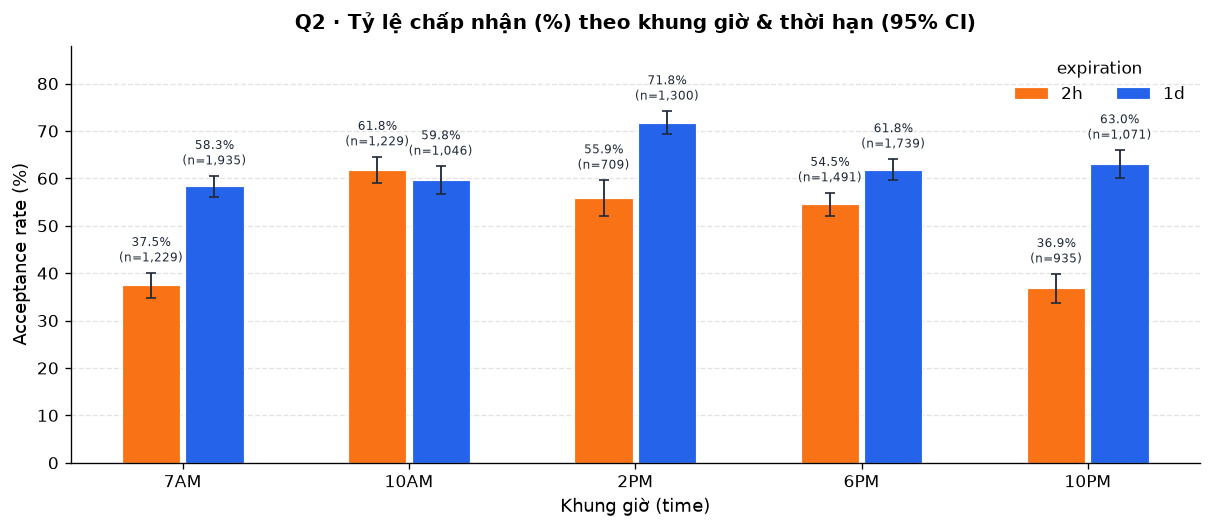

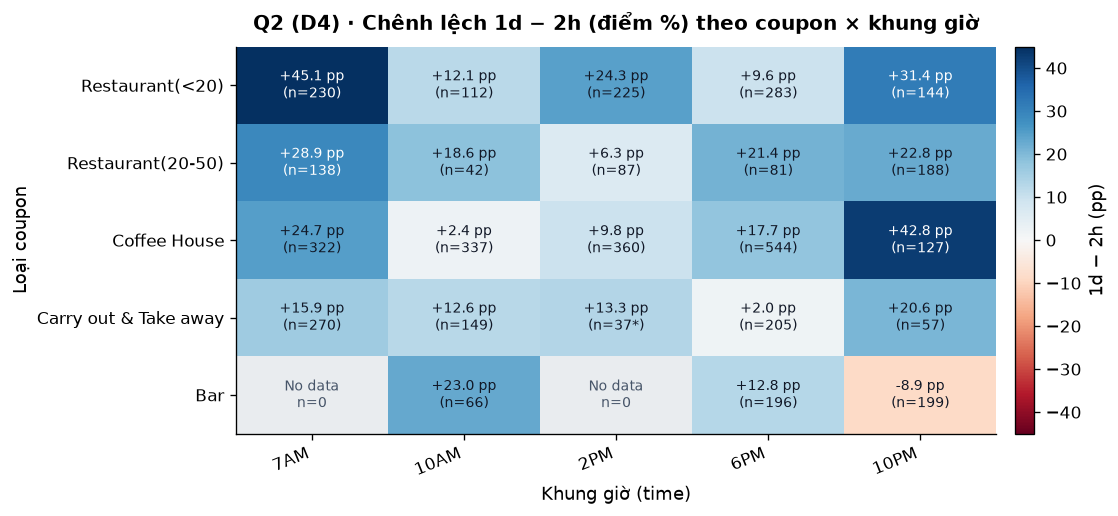

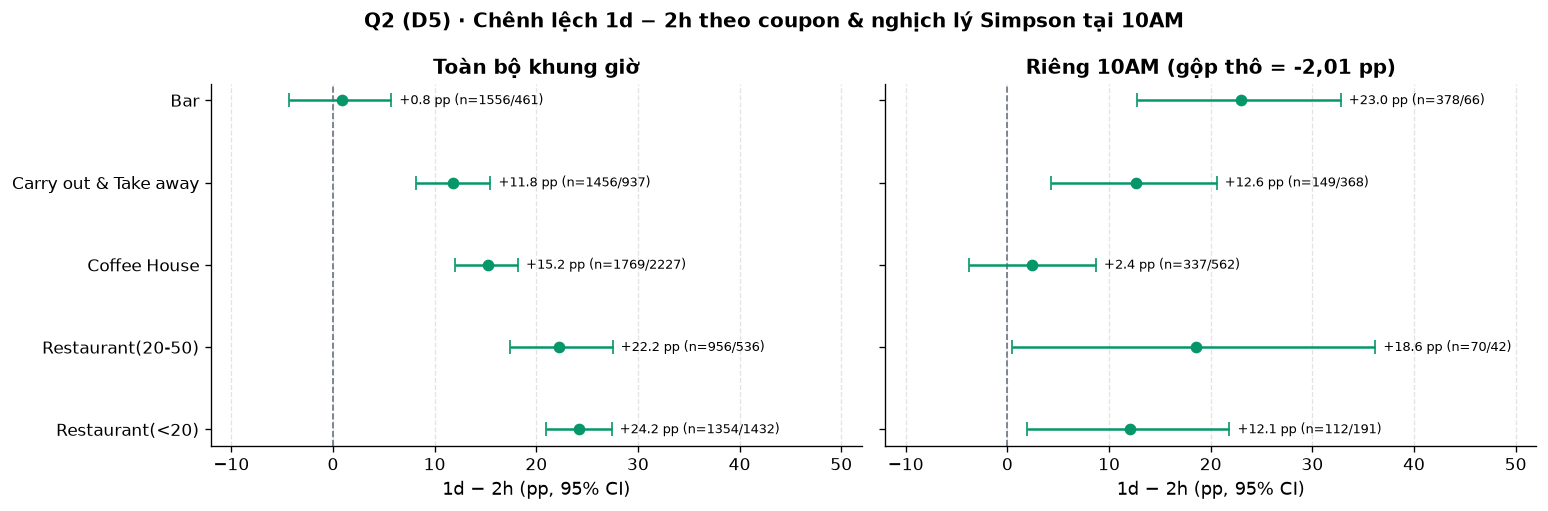

In [7]:
plot_bars_ci(
    rate_table(df, ["time", "expiration"], ci_method="bootstrap"), "time", "expiration",
    TIME_ORDER, EXPIRATION_ORDER,
    "Q2 · Tỷ lệ chấp nhận (%) theo khung giờ & thời hạn (95% CI)", "Khung giờ (time)",
    out_name="q2_fig1_grouped_bar_time_expiration",
    colors=["#F97316", "#2563EB"], figsize=(10.2, 4.5), ylim=(0, 88),
)
plt.show()

coupon_ord_q2 = ["Restaurant(<20)", "Restaurant(20-50)", "Coffee House",
                 "Carry out & Take away", "Bar"]
q2_plot = q2_tc_diff.assign(min_n=q2_tc_diff[["n_a", "n_b"]].min(axis=1))
diff_mat = (q2_plot.pivot(index="coupon", columns="time", values="diff_pp")
            .reindex(index=coupon_ord_q2, columns=TIME_ORDER))
min_mat = (q2_plot.pivot(index="coupon", columns="time", values="min_n")
           .reindex(index=coupon_ord_q2, columns=TIME_ORDER).fillna(0).astype(int))
plot_heatmap(
    diff_mat, min_mat,
    "Q2 (D4) · Chênh lệch 1d − 2h (điểm %) theo coupon × khung giờ",
    "Khung giờ (time)", "Loại coupon", "1d − 2h (pp)",
    out_name="q2_fig2_heatmap_diff_time_coupon", cmap="RdBu", vmin=-45, vmax=45,
    value_suffix=" pp", signed=True, min_n_warn=40, figsize=(9.8, 4.4),
)
plt.show()

set_style()
raw_10am = q2_tables["time"].set_index("time").loc["10AM", "diff_pp"]
raw_10am_text = f"{raw_10am:+.2f}".replace(".", ",")  # số thập phân kiểu Việt Nam
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
panels = [
    ("Toàn bộ khung giờ", q2_tables["coupon"]),
    (f"Riêng 10AM (gộp thô = {raw_10am_text} pp)", q2_tc_diff[q2_tc_diff["time"] == "10AM"]),
]
for ax, (sub_title, table) in zip(axes, panels):
    table = table.set_index("coupon").reindex(coupon_ord_q2)
    ax.axvline(0.0, color="#6B7280", linestyle="--", linewidth=1)
    for y, (coupon, row) in enumerate(table.iterrows()):
        val = row["diff_pp"]
        err_lo, err_hi = max(0.0, val - row["ci_low_pp"]), max(0.0, row["ci_high_pp"] - val)
        color = "#059669" if val >= 0 else "#DC2626"
        ax.errorbar(val, y, xerr=[[err_lo], [err_hi]], fmt="o", color=color, ecolor=color,
                    capsize=4)
        label = f"{val:+.1f} pp (n={int(row['n_a'])}/{int(row['n_b'])})"
        ax.text(val + err_hi + 0.8, y, label, va="center", fontsize=8)
    ax.set_yticks(range(len(table)), labels=table.index)
    ax.invert_yaxis()
    ax.set(xlim=(-12, 52), xlabel="1d − 2h (pp, 95% CI)", title=sub_title)
    ax.grid(axis="x", linestyle="--", alpha=0.35)

fig.suptitle("Q2 (D5) · Chênh lệch 1d − 2h theo coupon & nghịch lý Simpson tại 10AM",
             fontweight="bold")
fig.tight_layout()
save_figure(fig, "q2_fig3_coupon_expiration_ci")
plt.show()

#### Kết quả & kết luận Q2
- **Trả lời trực tiếp:** toàn mẫu, `1d` (**62,56%**, `n = 7.091`) cao hơn `2h` (**49,60%**, `n = 5.593`) **+12,96 pp** (95% CI `[11,27; 14,70]`). Chênh lệch dương ở 4/5 khung giờ, lớn nhất lúc `10PM` (**+26,13 pp**) và `7AM` (**+20,78 pp**); riêng `10AM` gộp thô là **−2,01 pp** (CI `[−5,78; 2,24]`, chứa 0).
- **Nghịch lý Simpson lúc `10AM` (D4):** khi so sánh trong từng loại coupon thì **cả 5/5 loại đều có ước lượng `1d > 2h`** (từ +2,41 đến +23,02 pp; 4/5 có CI không chứa 0, riêng `Coffee House` +2,41 pp có CI `[−3,82; 8,70]`). Bảng gộp bị kéo xuống vì nhóm `1d` lúc 10AM chứa **36,1%** coupon `Bar` (loại ít được nhận) so với **5,4%** ở nhóm `2h`.
- **Theo loại coupon:** `1d` hơn `2h` rõ ở `Restaurant(<20)` (**+24,22 pp**), `Restaurant(20-50)` (**+22,24 pp**), `Coffee House` (**+15,20 pp**), `Carry out & Take away` (**+11,78 pp**); riêng `Bar` gần như không khác (**+0,85 pp**, CI `[−4,30; 5,73]`). Lúc `10PM`, `Bar` nghiêng về `2h` (**−8,87 pp**) nhưng CI `[−18,37; 0,14]` chứa 0, còn lúc `6PM` lại ngược chiều (`1d` cao hơn **+12,82 pp**, CI `[4,32; 21,28]`) → **không** có bằng chứng cho nhận định "`Bar` buổi tối hợp `2h`".
- **Điểm bất ngờ:** nhìn bảng gộp lúc 10AM dễ kết luận "hạn ngắn tốt hơn", nhưng đó chỉ là ảo ảnh do cơ cấu loại coupon khác nhau giữa hai nhóm thời hạn.
- **Ứng dụng có điều kiện:** mặc định ưu tiên hạn `1d` cho các coupon ăn uống; với `Bar`, thời hạn hầu như không tạo khác biệt nên có thể chọn theo mục tiêu kinh doanh (cần thử nghiệm thêm).
- **Hạn chế:** `Bar` không có coupon `2h` lúc `7AM` và `2PM` (ô rỗng, `n = 0`); `time` gắn chặt với `destination` (`7AM` = 100% `Work`; `10AM`, `2PM` = 100% `No Urgent Place`) nên khác biệt theo giờ một phần là khác biệt theo điểm đến; CI bootstrap theo dòng.

---
## Phase 2.2 · Thói quen tiêu dùng & Người đồng hành *(Nguyễn Mạnh Hà — Q3 & Q4)*

### Q3 · Sự phù hợp giữa loại coupon và thói quen ghé thăm (`D3, D4, D5, D6`)
- **Câu hỏi:** Trong cùng loại coupon, người có thói quen ghé địa điểm tương ứng thường xuyên hơn có tỷ lệ chấp nhận cao hơn không?
- **Lợi ích khi trả lời được:** nếu thói quen khớp với loại coupon thật sự đi kèm tỷ lệ nhận cao hơn, hệ thống có cơ sở **cá nhân hóa** (gửi coupon quán cà phê cho người hay đi cà phê) thay vì gửi đại trà gây phiền.

#### Tiền xử lý
1. **Tạo biến mới `matched_frequency` (D3):** với mỗi dòng, lấy tần suất ở đúng cột thói quen khớp loại coupon (`Coffee House` → `CoffeeHouse`, `Bar` → `Bar`, `Carry out & Take away` → `CarryAway`, `Restaurant(<20)` → `RestaurantLessThan20`, `Restaurant(20-50)` → `Restaurant20To50`).
2. Không đổi ô thiếu thành `never`: khi mô tả, ô thiếu thành nhóm `Unknown`; khi so sánh dùng 2 cách — **complete-case** (bỏ dòng thiếu, cách chính) và **điền mức phổ biến nhất trong cùng coupon** (độ nhạy).
3. **Định nghĩa "thường xuyên":** ngưỡng chính `≥ 1 lần/tháng` (`1~3`, `4~8`, `gt8`); ngưỡng độ nhạy `≥ 4 lần/tháng` (`4~8`, `gt8`).

In [8]:
q3 = df.copy()
q3["matched_frequency"] = matched_frequency(q3)
q3["frequency_display"] = q3["matched_frequency"].fillna("Unknown")  # chỉ dùng để mô tả
print("Số dòng thiếu matched_frequency:", int(q3["matched_frequency"].isna().sum()))

THRESHOLDS = {"at_least_1": ["1~3", "4~8", "gt8"], "at_least_4": ["4~8", "gt8"]}


def handle_missing(data, method):
    '''complete_case: bỏ dòng thiếu;
    within_coupon_mode: điền mức phổ biến nhất trong cùng coupon.'''
    if method == "complete_case":
        return data[data["matched_frequency"].notna()].copy()
    work = data.copy()
    modes = work.groupby("coupon")["matched_frequency"].transform(lambda s: s.mode().iloc[0])
    work["matched_frequency"] = work["matched_frequency"].fillna(modes)
    return work


for method in ["complete_case", "within_coupon_mode"]:
    print(row_count_log(len(q3), len(handle_missing(q3, method)), f"Q3 {method}"))

Số dòng thiếu matched_frequency: 164
Q3 complete_case: 12,684 -> 12,520 rows (delta -164)
Q3 within_coupon_mode: 12,684 -> 12,684 rows (delta +0)


#### Phân tích
1. Tỷ lệ chấp nhận theo từng mức tần suất trong từng coupon (Wilson 95% CI) — phần mô tả, dùng cho hình.
2. **So sánh trong từng coupon (D4):** chênh lệch "thường xuyên − ít ghé" (pp) với 95% bootstrap CI, `n_boot = 10.000` (D5).
3. **Độ bền (D6):** lặp lại với 2 ngưỡng × 2 cách xử lý thiếu = 4 biến thể, và với dữ liệu đã bỏ 74 dòng trùng; kết luận được coi là bền nếu chiều chênh lệch không đổi.

In [9]:
freq_rates = rate_table(q3, ["coupon", "frequency_display"])  # tỷ lệ theo mức tần suất


def frequent_contrast(work, levels, key):
    '''Chênh tỷ lệ nhận giữa người đến thường (mức thuộc levels) và người ít đến,
    tính trong từng coupon.'''
    work = work.assign(frequent=work["matched_frequency"].isin(levels).astype(int))
    return contrasts(work, ["coupon"], "frequent", 1, 0, n_boot=10000, seed=17104, key=key)


# D6: 2 ngưỡng × 2 cách xử lý thiếu = 4 biến thể
variants = []
for th_name, levels in THRESHOLDS.items():
    for method in ["complete_case", "within_coupon_mode"]:
        res = frequent_contrast(handle_missing(q3, method), levels, key=("q3", th_name, method))
        variants.append(res.assign(threshold=th_name, missing_method=method))

q3_sens = pd.concat(variants, ignore_index=True)
is_cc = q3_sens["missing_method"] == "complete_case"
q3_primary = q3_sens[(q3_sens["threshold"] == "at_least_1") & is_cc].copy()
save_table(q3_primary, "q3_primary_contrasts")
save_table(q3_sens, "q3_sensitivity")

show_cols = ["coupon", "n_a", "rate_a_pct", "n_b", "rate_b_pct", "diff_pp", "ci_low_pp",
             "ci_high_pp"]
display(q3_primary[show_cols])
display(q3_sens.groupby("coupon").agg(
    min_pp=("diff_pp", "min"), max_pp=("diff_pp", "max"),
    pos=("diff_pp", lambda s: int((s > 0).sum())),
))
print("Biến thể ngưỡng >= 4 lần/tháng (complete-case):")
display(q3_sens[(q3_sens["threshold"] == "at_least_4") & is_cc][show_cols])

print("Hai mức tần suất cao nhất (càng ghé nhiều có càng nhận nhiều không?):")
top_levels = freq_rates[freq_rates["frequency_display"].isin(["4~8", "gt8"])]
display(top_levels[["coupon", "frequency_display", "n", "rate_pct", "ci_low_pct",
                    "ci_high_pct"]])

# Độ bền: bỏ dòng trùng hoàn toàn rồi tính lại biến thể chính
q3_dedup_src = q3.drop_duplicates()
print(row_count_log(len(q3), len(q3_dedup_src), "Q3 sensitivity drop exact duplicates"))
q3_dedup = frequent_contrast(handle_missing(q3_dedup_src, "complete_case"),
                             THRESHOLDS["at_least_1"], key="q3_dedup")
change = np.abs(q3_dedup["diff_pp"].to_numpy() - q3_primary["diff_pp"].to_numpy())
print(f"Max |diff_pp| change after dropping duplicates: {change.max():.2f} pp")

,coupon,n_a,rate_a_pct,n_b,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp
0,Bar,596,68.79,1400,29.21,39.58,35.18,43.97
1,Carry out & Take away,1986,74.37,385,68.57,5.80,0.84,10.91
2,Coffee House,1922,66.02,2002,34.62,31.41,28.42,34.38
3,Restaurant(20-50),506,55.53,964,38.38,17.15,11.84,22.41
4,Restaurant(<20),2245,71.54,514,66.15,5.39,0.93,9.92


,min_pp,max_pp,pos
coupon,,,
Bar,39.45,39.82,4
Carry out & Take away,2.65,5.93,4
Coffee House,22.54,31.41,4
Restaurant(20-50),17.15,21.93,4
Restaurant(<20),3.57,5.60,4


Biến thể ngưỡng >= 4 lần/tháng (complete-case):


,coupon,n_a,rate_a_pct,n_b,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp
10,Bar,199,76.88,1797,37.06,39.82,33.46,46.01
11,Carry out & Take away,1122,74.96,1249,72.06,2.90,-0.72,6.45
12,Coffee House,880,67.50,3044,44.94,22.56,18.95,26.05
13,Restaurant(20-50),123,64.23,1347,42.46,21.76,12.81,30.55
14,Restaurant(<20),1088,72.89,1671,69.00,3.89,0.48,7.34


Hai mức tần suất cao nhất (càng ghé nhiều có càng nhận nhiều không?):


,coupon,frequency_display,n,rate_pct,ci_low_pct,ci_high_pct
1,Bar,4~8,150,78.00,70.72,83.88
3,Bar,gt8,49,73.47,59.74,83.79
7,Carry out & Take away,4~8,820,75.37,72.30,78.19
9,Carry out & Take away,gt8,302,73.84,68.61,78.48
13,Coffee House,4~8,538,68.59,64.55,72.37
15,Coffee House,gt8,342,65.79,60.61,70.62
19,Restaurant(20-50),4~8,91,62.64,52.38,71.88
21,Restaurant(20-50),gt8,32,68.75,51.43,82.05
25,Restaurant(<20),4~8,800,71.75,68.53,74.76
27,Restaurant(<20),gt8,288,76.04,70.79,80.61


Q3 sensitivity drop exact duplicates: 12,684 -> 12,610 rows (delta -74)
Max |diff_pp| change after dropping duplicates: 0.29 pp


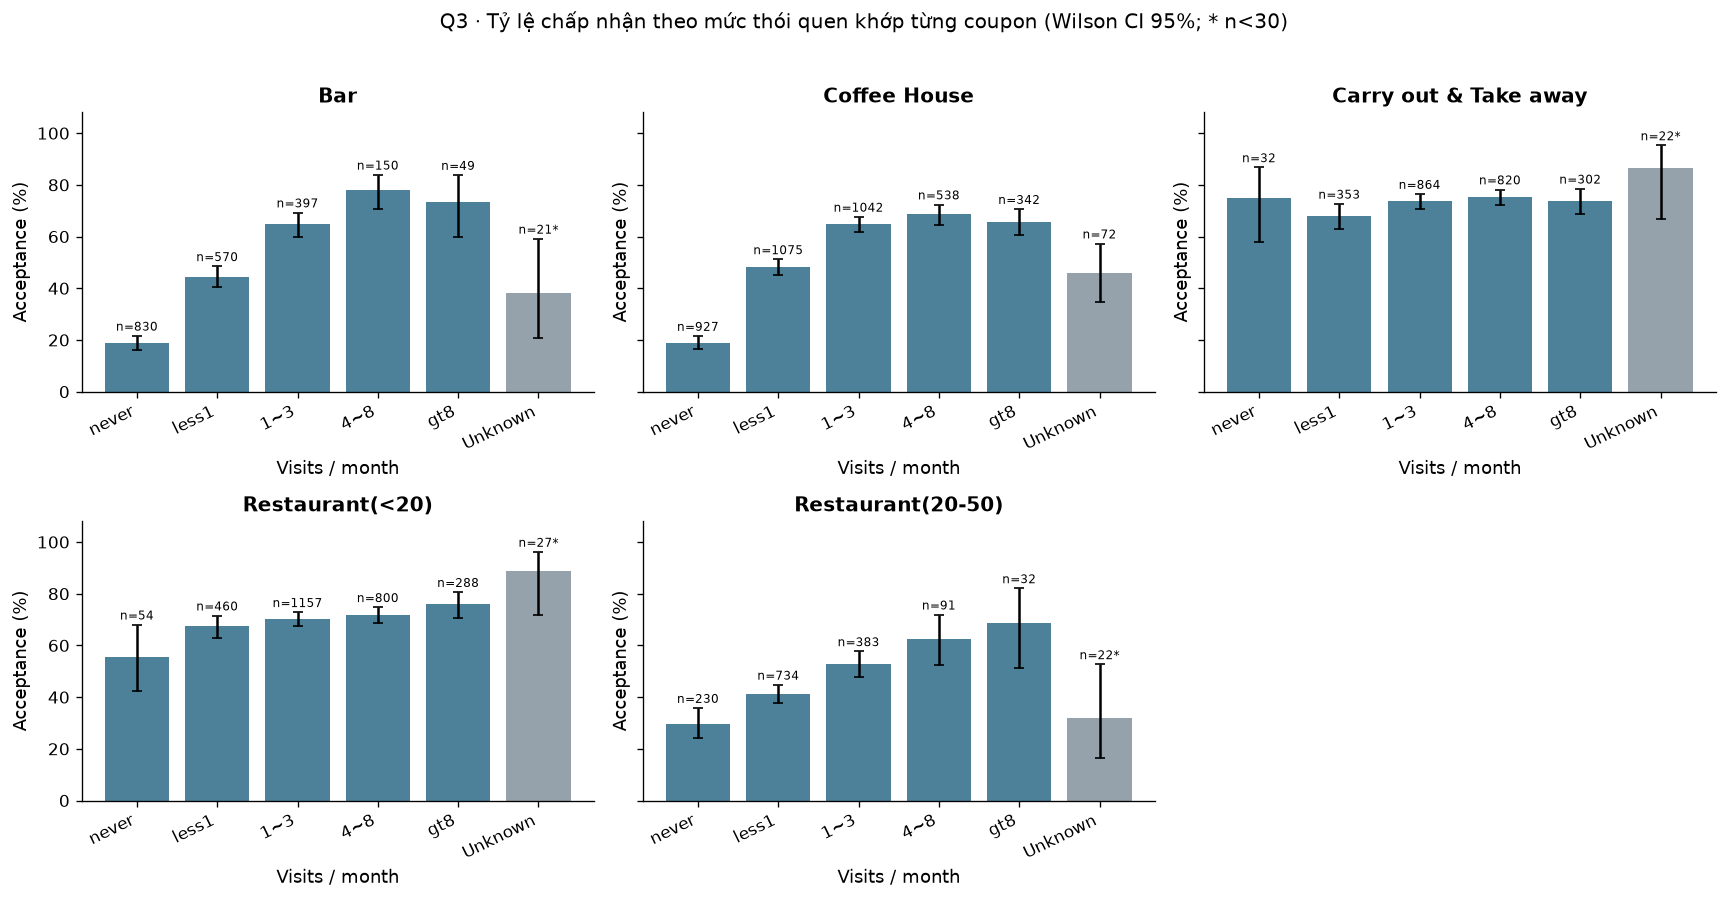

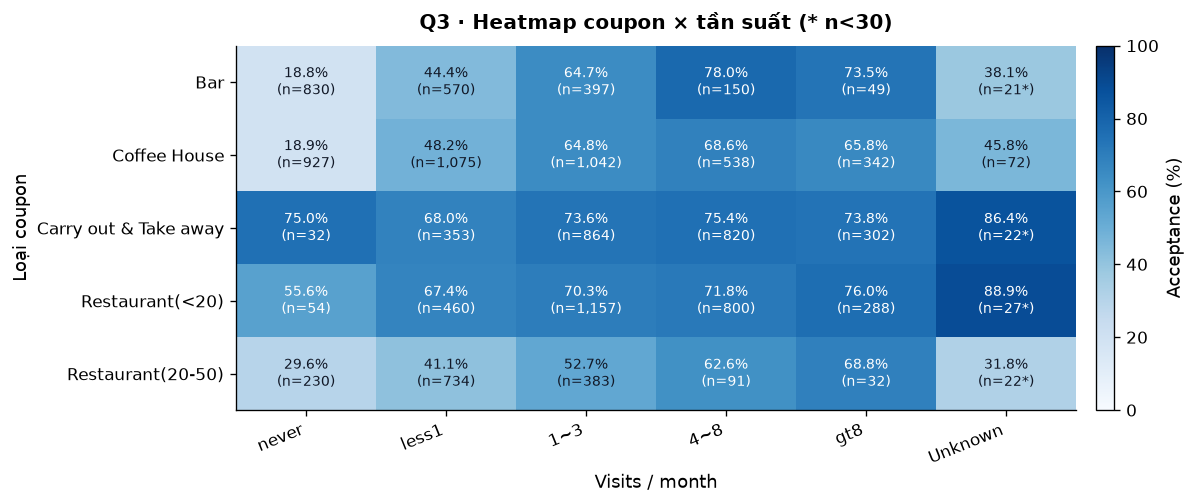

In [10]:
set_style()
freq_ord = FREQUENCIES + ["Unknown"]
fig, axes = plt.subplots(2, 3, figsize=(14.5, 7.6), sharey=True)
for ax, coupon in zip(axes.flat, COUPONS):
    sub = (freq_rates[freq_rates["coupon"] == coupon]
           .set_index("frequency_display").reindex(freq_ord))
    for i, lvl in enumerate(freq_ord):
        r = sub.loc[lvl]
        if pd.isna(r["n"]):
            ax.text(i, 3, "n=0", ha="center", fontsize=7)
            continue
        yerr = np.array([[max(0.0, r["rate_pct"] - r["ci_low_pct"])],
                         [max(0.0, r["ci_high_pct"] - r["rate_pct"])]])
        bar_color = "#8795a1" if lvl == "Unknown" else "#346e8b"
        ax.bar(i, r["rate_pct"], color=bar_color, alpha=0.88)
        ax.errorbar(i, r["rate_pct"], yerr=yerr, fmt="none", color="black", capsize=3)
        star = "*" if r["n"] < MIN_N else ""
        ax.text(i, min(101, r["ci_high_pct"] + 2), f"n={int(r['n'])}{star}",
                ha="center", fontsize=7)
    ax.set(title=coupon, xlabel="Visits / month", ylabel="Acceptance (%)", ylim=(0, 108))
    ax.set_xticks(range(len(freq_ord)), freq_ord, rotation=26, ha="right")
axes.flat[-1].axis("off")
fig.suptitle("Q3 · Tỷ lệ chấp nhận theo mức thói quen khớp từng coupon (Wilson CI 95%; * n<30)")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_figure(fig, "q3_frequency_bars")
plt.show()

r_q3 = (freq_rates.pivot(index="coupon", columns="frequency_display", values="rate_pct")
        .reindex(index=COUPONS, columns=freq_ord))
c_q3 = (freq_rates.pivot(index="coupon", columns="frequency_display", values="n")
        .reindex(index=COUPONS, columns=freq_ord).fillna(0).astype(int))
plot_heatmap(r_q3, c_q3, "Q3 · Heatmap coupon × tần suất (* n<30)", "Visits / month",
             "Loại coupon", "Acceptance (%)", out_name="q3_frequency_heatmap",
             cmap="Blues", vmin=0, vmax=100, figsize=(10.6, 4.3))
plt.show()

#### Kết quả & kết luận Q3
- **Trả lời trực tiếp: có, rõ nhất ở `Bar`, `Coffee House` và `Restaurant(20-50)`.** Trong cả **5/5 loại coupon**, tỷ lệ nhận của nhóm ghé thường xuyên (`≥ 1 lần/tháng`) đều cao hơn nhóm ít ghé: mạnh nhất ở `Bar` (**68,79%** vs **29,21%**, **+39,58 pp**, CI `[35,18; 43,97]`) và `Coffee House` (**66,02%** vs **34,62%**, **+31,41 pp**, CI `[28,42; 34,38]`), tiếp theo `Restaurant(20-50)` (**+17,15 pp**), `Carry out & Take away` (**+5,80 pp**) và `Restaurant(<20)` (**+5,39 pp**).
- **Độ bền (D6):** chiều dương giữ nguyên ở cả 4/4 biến thể ngưỡng × cách xử lý thiếu; bỏ 74 dòng trùng chỉ đổi tối đa **0,29 pp**. Riêng `Carry out & Take away` khi siết ngưỡng `≥ 4 lần/tháng` chỉ còn **+2,90 pp** với CI `[−0,72; 6,45]` cắt qua 0 → kết luận cho loại coupon này yếu (Phase 2.4 kiểm tra thêm bằng CI theo người).
- **Điểm bất ngờ:** không phải "càng ghé nhiều càng nhận nhiều": với `Bar`, mức `gt8` (**73,47%**, `n = 49`) không cao hơn mức `4~8` (**78,00%**, `n = 150`); `Coffee House` cũng vậy (65,79% so với 68,59%). CI của hai mức chồng lấn nên chỉ nói được tỷ lệ **chững lại** ở mức cao nhất.
- **Ứng dụng có điều kiện:** ưu tiên gửi coupon `Bar`/`Coffee House` cho người có thói quen tương ứng; với đồ mang đi và nhà hàng bình dân, thói quen chỉ phân biệt yếu nên cần thêm tín hiệu khác (khoảng cách, thời hạn — Q1, Q2).
- **Hạn chế:** tần suất là tự khai theo khoảng; `164` dòng thiếu (`1,29%`); bootstrap theo dòng chưa tính việc một người trả lời nhiều tình huống — khi tính lại CI theo người (Phase 2.4), `Carry out & Take away` và `Restaurant(<20)` có CI chứa 0, nên kết luận chắc chắn chỉ áp dụng cho `Bar`, `Coffee House` và `Restaurant(20-50)`.

### Q4 · Người đồng hành (`passanger`) & giới hạn common support (`D4, D5`)
- **Câu hỏi:** Người đồng hành (`passanger`) liên hệ ra sao với tỷ lệ chấp nhận sau khi kiểm soát loại coupon và mục đích hành trình (`destination`)?
- **Lợi ích khi trả lời được:** cho biết hệ thống có nên dùng tín hiệu "đang đi cùng bạn bè/người yêu" khi gợi ý hay không, hay khác biệt nhìn thấy chỉ do bối cảnh chuyến đi (đi chơi thường đi cùng bạn bè) — tránh xây quy tắc gợi ý dựa trên một tương quan giả.

#### Tiền xử lý
1. Không bỏ dòng khỏi dữ liệu gốc; với mỗi cặp so sánh chỉ giữ dòng của 2 nhóm: `Friend(s) − Alone` và `Partner − Alone` (hai cặp có đủ dữ liệu).
2. **Tầng kiểm soát:** `coupon × destination` (15 tầng) và thêm `has_children` (30 tầng). Một tầng chỉ được dùng khi **cả hai nhóm đều có `n ≥ 30`** (*common support*); tỷ lệ mẫu thuộc các tầng được dùng gọi là `coverage`.

In [11]:
pairs = {grp: df[df["passanger"].isin([grp, "Alone"])] for grp in ["Friend(s)", "Partner"]}
for grp, pair in pairs.items():
    print(row_count_log(len(df), len(pair), f"Q4 keep {grp} & Alone rows"))

Q4 keep Friend(s) & Alone rows: 12,684 -> 10,603 rows (delta -2,081)
Q4 keep Partner & Alone rows: 12,684 -> 8,380 rows (delta -4,304)


#### Phân tích
1. Chênh lệch **thô** (gộp mọi bối cảnh) với 95% bootstrap CI.
2. **Chuẩn hóa (D4):** tính chênh lệch trong từng tầng common support rồi lấy trung bình có trọng số `w_s = (n_A,s + n_B,s) / Σ(n_A + n_B)`; CI 95% bằng bootstrap trong từng tầng (D5, `n_boot = 10.000`).
3. Đếm số tầng đủ mẫu có chênh lệch **ngược dấu** với mức thô để thấy kết luận gộp thô dễ sai thế nào.

In [12]:
coupon_pass = rate_table(df, ["coupon", "passanger"])
joint_pass = rate_table(df, ["coupon", "destination", "passanger"])

BOOT = {"n_boot": 10000, "seed": 17104}
crude_rows, joint_list, std_rows = [], [], []
for grp, pair in pairs.items():
    label = f"{grp} - Alone"
    c_crude = contrasts(pair, [], "passanger", grp, "Alone", **BOOT, key=("q4_crude", grp))
    c_joint = contrasts(pair, ["coupon", "destination"], "passanger", grp, "Alone", **BOOT,
                        key=("q4_joint", grp))
    c_child = contrasts(pair, ["coupon", "destination", "has_children"], "passanger", grp,
                        "Alone", **BOOT, key=("q4_child", grp))
    crude_rows.append(c_crude.assign(comparison=label))
    joint_list.append(c_joint.assign(comparison=label))
    for adj, strata_table in [("coupon_destination", c_joint),
                              ("coupon_destination_children", c_child)]:
        std = standardized_contrast(strata_table, **BOOT, key=("q4_std", adj, grp))
        std_rows.append({"comparison": label, "adjustment": adj, **std})

crude_df = pd.concat(crude_rows, ignore_index=True)
std_df = pd.DataFrame(std_rows)
q4_joint = pd.concat(joint_list, ignore_index=True)
q4_summary = pd.concat([crude_df.assign(type="crude"), std_df.assign(type="standardized")],
                       ignore_index=True)
save_table(q4_summary, "q4_crude_vs_standardized")
save_table(q4_joint, "q4_common_support_strata")

pair_cols = ["n_a", "rate_a_pct", "n_b", "rate_b_pct", "diff_pp", "ci_low_pp", "ci_high_pp"]
display(crude_df[["comparison", *pair_cols]])
display(std_df[["comparison", "adjustment", "n_strata_used", "n_strata_total", "coverage",
                "diff_pp", "ci_low_pp", "ci_high_pp"]])
friend_ok = q4_joint[(q4_joint["status"] == "ok") & (q4_joint["comparison"] == "Friend(s) - Alone")]
display(friend_ok[["coupon", "destination", *pair_cols]])

# Tầng đủ mẫu (status "ok") có chênh lệch ngược dấu với chênh lệch thô của cùng cặp
crude_sign = np.sign(crude_df.set_index("comparison")["diff_pp"])
ok_strata = q4_joint[q4_joint["status"] == "ok"].copy()
ok_strata["doi_dau"] = np.sign(ok_strata["diff_pp"]) != ok_strata["comparison"].map(crude_sign)
ok_strata["ci_khong_chua_0"] = (ok_strata["ci_low_pp"] > 0) | (ok_strata["ci_high_pp"] < 0)
display(ok_strata[["comparison", "coupon", "destination", "n_a", "n_b", "diff_pp",
                   "ci_low_pp", "ci_high_pp", "doi_dau", "ci_khong_chua_0"]])
n_flip = int(ok_strata["doi_dau"].sum())
n_flip_sig = int((ok_strata["doi_dau"] & ok_strata["ci_khong_chua_0"]).sum())
print(f"Tầng đủ mẫu đổi dấu so với chênh lệch thô: {n_flip}/{len(ok_strata)} "
      f"(trong đó CI không chứa 0: {n_flip_sig})")

# Chênh lệch thô CHỈ trong các tầng đủ mẫu: tách phần "thu hẹp về tầng so sánh được"
# khỏi phần "cân lại cơ cấu coupon" của chuẩn hóa
kept = ok_strata.groupby("comparison")[["accepted_a", "n_a", "accepted_b", "n_b"]].sum()
kept["tho_trong_tang_giu_pp"] = (kept["accepted_a"] / kept["n_a"]
                                 - kept["accepted_b"] / kept["n_b"]) * 100
display(kept.round(2))

,comparison,n_a,rate_a_pct,n_b,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp
0,Friend(s) - Alone,3298,67.34,7305,52.58,14.76,12.81,16.75
1,Partner - Alone,1075,59.53,7305,52.58,6.95,3.83,10.07


,comparison,adjustment,n_strata_used,n_strata_total,coverage,diff_pp,ci_low_pp,ci_high_pp
0,Friend(s) - Alone,coupon_destination,4,15,0.4163,1.33,-1.70,4.51
1,Friend(s) - Alone,coupon_destination_children,7,30,0.3850,2.15,-0.98,5.29
2,Partner - Alone,coupon_destination,8,15,0.5364,3.03,-1.08,7.07
3,Partner - Alone,coupon_destination_children,8,30,0.3394,2.31,-2.34,6.84


,coupon,destination,n_a,rate_a_pct,n_b,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp
1,Bar,No Urgent Place,337,55.79,291,37.80,17.99,10.29,25.66
4,Carry out & Take away,No Urgent Place,739,75.78,75,84.00,-8.22,-16.67,1.00
7,Coffee House,No Urgent Place,1228,59.69,473,58.56,1.13,-4.13,6.43
13,Restaurant(<20),No Urgent Place,826,80.15,445,80.67,-0.53,-5.09,4.07


,comparison,coupon,destination,n_a,n_b,diff_pp,ci_low_pp,ci_high_pp,doi_dau,ci_khong_chua_0
1,Friend(s) - Alone,Bar,No Urgent Place,337,291,17.99,10.29,25.66,False,True
4,Friend(s) - Alone,Carry out & Take away,No Urgent Place,739,75,-8.22,-16.67,1.00,True,False
7,Friend(s) - Alone,Coffee House,No Urgent Place,1228,473,1.13,-4.13,6.43,False,False
13,Friend(s) - Alone,Restaurant(<20),No Urgent Place,826,445,-0.53,-5.09,4.07,True,False
15,Partner - Alone,Bar,Home,60,422,-19.30,-31.21,-6.45,True,True
16,Partner - Alone,Bar,No Urgent Place,214,291,4.26,-4.36,12.83,False,False
18,Partner - Alone,Carry out & Take away,Home,61,568,-3.94,-15.06,6.49,True,False
19,Partner - Alone,Carry out & Take away,No Urgent Place,36,75,-17.33,-35.22,-0.66,True,True
21,Partner - Alone,Coffee House,Home,58,870,20.23,7.35,33.22,False,True
22,Partner - Alone,Coffee House,No Urgent Place,247,473,-1.07,-8.70,6.52,True,False


Tầng đủ mẫu đổi dấu so với chênh lệch thô: 6/12 (trong đó CI không chứa 0: 2)


,accepted_a,n_a,accepted_b,n_b,tho_trong_tang_giu_pp
comparison,,,,,
Friend(s) - Alone,2143,3130,809,1284,5.46
Partner - Alone,551,934,1997,3561,2.91


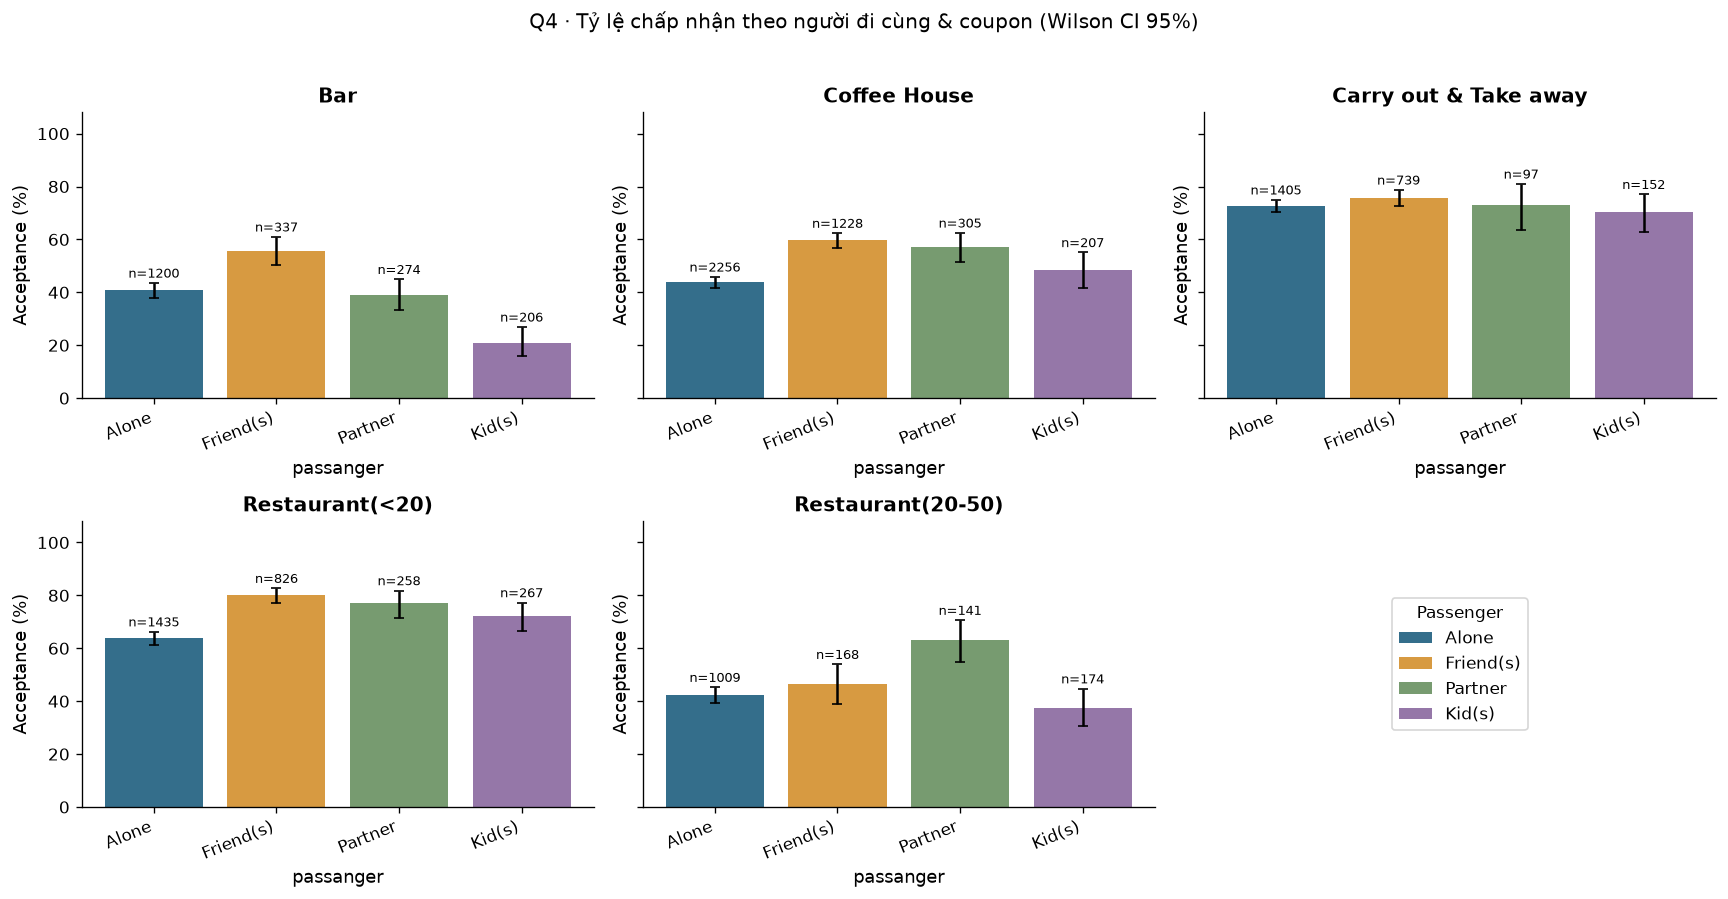

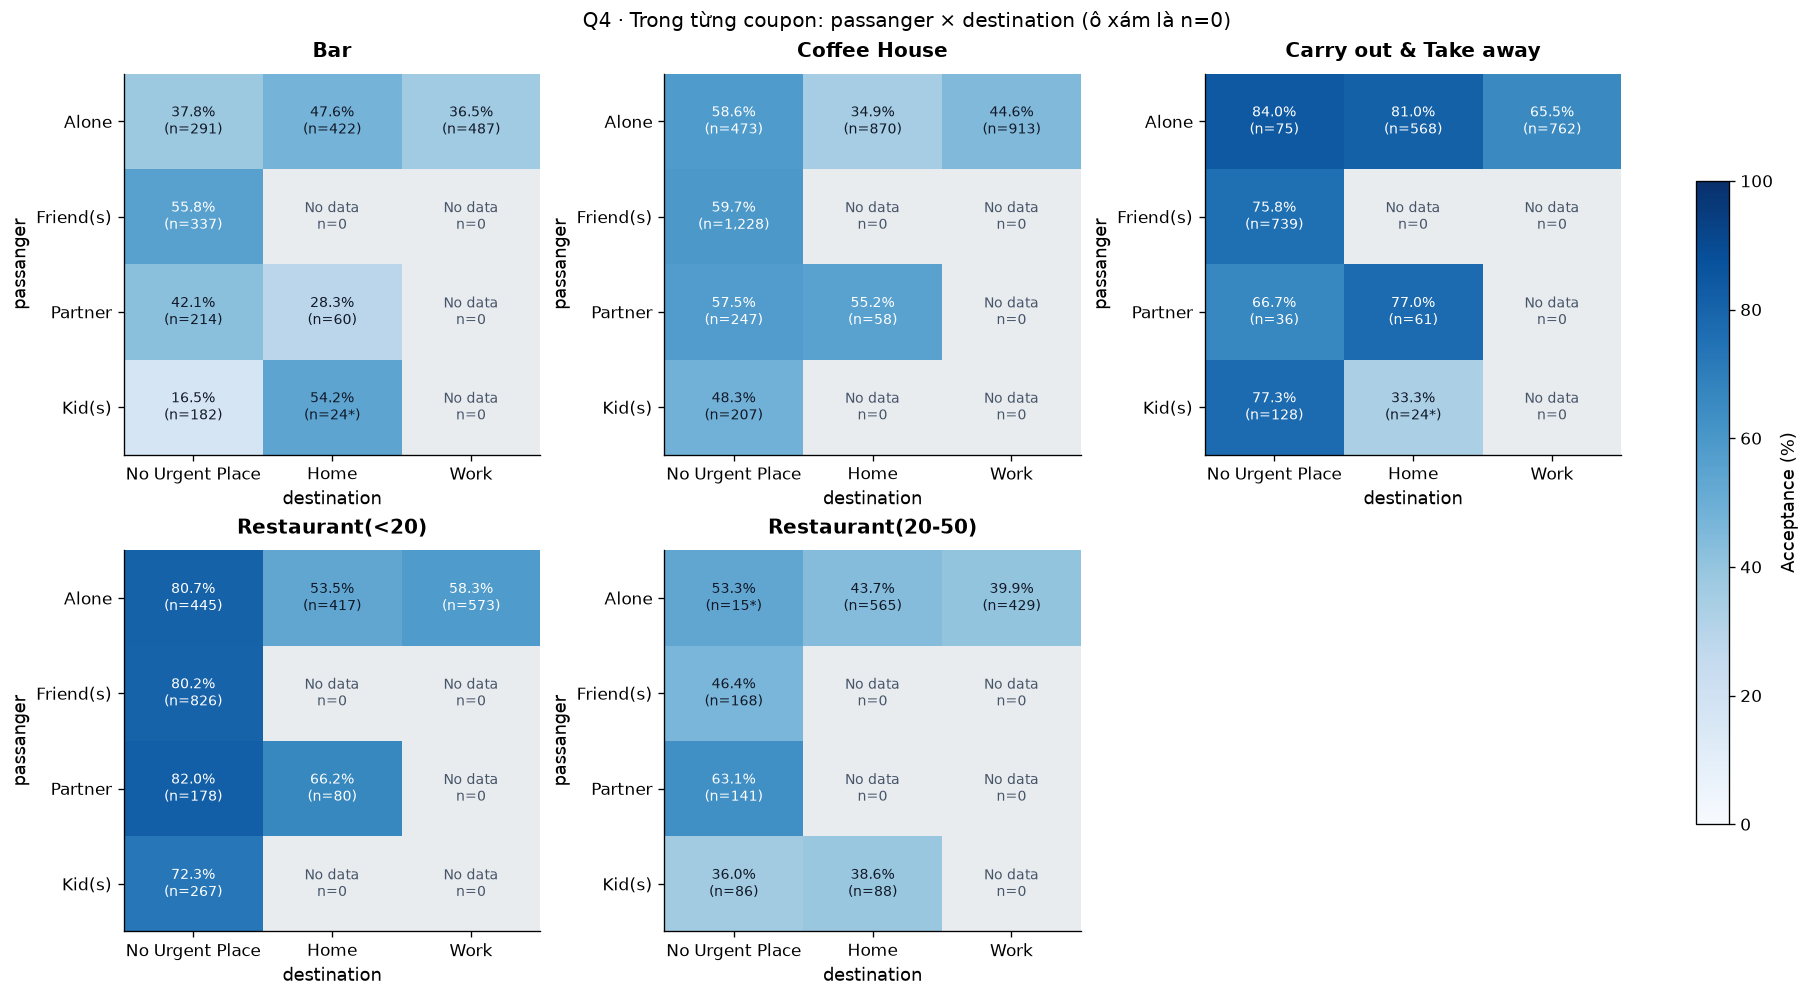

In [13]:
set_style()
fig, axes = plt.subplots(2, 3, figsize=(14.5, 7.6), sharey=True)
colors = ["#346e8b", "#d79a41", "#779b70", "#9577a8"]
for ax, coupon in zip(axes.flat, COUPONS):
    part = coupon_pass[coupon_pass["coupon"] == coupon].set_index("passanger").reindex(PASSENGERS)
    for i, p in enumerate(PASSENGERS):
        r = part.loc[p]
        if pd.isna(r["n"]):
            continue
        yerr = np.array([[max(0.0, r["rate_pct"] - r["ci_low_pct"])],
                         [max(0.0, r["ci_high_pct"] - r["rate_pct"])]])
        ax.bar(i, r["rate_pct"], color=colors[i], label=p)
        ax.errorbar(i, r["rate_pct"], yerr=yerr, fmt="none", color="black", capsize=3)
        ax.text(i, min(101, r["ci_high_pct"] + 2), f"n={int(r['n'])}", ha="center", fontsize=8)
    ax.set(title=coupon, xlabel="passanger", ylabel="Acceptance (%)", ylim=(0, 108))
    ax.set_xticks(range(4), PASSENGERS, rotation=22, ha="right")
axes.flat[-1].axis("off")
h, l = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(h, l, loc="center", title="Passenger")
fig.suptitle("Q4 · Tỷ lệ chấp nhận theo người đi cùng & coupon (Wilson CI 95%)")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_figure(fig, "q4_passanger_bars")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15.0, 8.2), constrained_layout=True)
for ax, coupon in zip(axes.flat, COUPONS):
    sub = joint_pass[joint_pass["coupon"] == coupon]
    r_mat = (sub.pivot(index="passanger", columns="destination", values="rate_pct")
             .reindex(index=PASSENGERS, columns=DESTINATIONS))
    c_mat = (sub.pivot(index="passanger", columns="destination", values="n")
             .reindex(index=PASSENGERS, columns=DESTINATIONS).fillna(0).astype(int))
    _, _, img = plot_heatmap(r_mat, c_mat, coupon, "destination", "passanger",
                             cmap="Blues", vmin=0, vmax=100, ax=ax)
axes.flat[-1].axis("off")
fig.colorbar(img, ax=list(axes.flat), shrink=0.75, label="Acceptance (%)")
fig.suptitle("Q4 · Trong từng coupon: passanger × destination (ô xám là n=0)")
save_figure(fig, "q4_destination_heatmaps")
plt.show()

#### Kết quả & kết luận Q4
- **Trả lời trực tiếp:** gộp thô, đi cùng bạn bè có tỷ lệ nhận cao hơn đi một mình **+14,76 pp** (CI `[12,81; 16,75]`), đi cùng bạn đời cao hơn **+6,95 pp** (CI `[3,83; 10,07]`). Nhưng sau khi **chuẩn hóa theo `coupon × destination`** chỉ còn **+1,33 pp** (CI `[−1,70; 4,51]`) và **+3,03 pp** (CI `[−1,08; 7,07]`) — cả hai CI đều chứa 0 → phần lớn khác biệt thô đến từ **bối cảnh chuyến đi**, không phải từ người đi cùng.
- **Vì sao:** `Friend(s)` chỉ xuất hiện khi đi `No Urgent Place` (nơi tỷ lệ nhận vốn cao) và không có dòng nào ở `Home`/`Work`; chỉ `4/15` tầng (`41,6%` mẫu của cặp) đủ common support. Vì vậy `+1,33 pp` là chênh lệch trung bình **trong 4 tầng `No Urgent Place`** đó, không phải trên toàn mẫu: riêng việc thu hẹp về các tầng này đã kéo chênh lệch thô từ +14,76 xuống **+5,46 pp**, phần cân lại cơ cấu coupon giảm tiếp còn +1,33 pp. Thêm `has_children` vào tầng cho kết luận tương tự (`Friend(s) − Alone` **+2,15 pp**, CI chứa 0).
- **Khác biệt theo coupon:** trong `Bar` tại `No Urgent Place`, `Friend(s)` vẫn cao hơn `Alone` **+17,99 pp** (CI `[10,29; 25,66]`); ngược lại ở `Carry out & Take away` là **−8,22 pp** (CI chứa 0). Trong `12` tầng đủ mẫu của hai cặp, `6/12` có chênh lệch ngược dấu với mức thô nhưng chỉ `2` tầng trong số đó có CI không chứa 0 → chiều khác biệt phụ thuộc bối cảnh và phần lớn chưa chắc chắn.
- **Điểm bất ngờ:** chênh lệch lớn nhất trong bảng thô (+14,76 pp) gần như biến mất khi so sánh đúng bối cảnh — ví dụ điển hình của biến nhiễu (confounder).
- **Ứng dụng có điều kiện:** không nên dùng "đi cùng bạn bè" làm tín hiệu gợi ý chung; có thể cân nhắc riêng cho coupon `Bar` trong chuyến đi không gấp.
- **Hạn chế:** thiếu common support ở `Home`/`Work` cho `Friend(s)` nên không kết luận được cho các bối cảnh đó; `has_children` là "có con" chứ không chắc trẻ đang ngồi trên xe; CI bootstrap theo dòng.

---
## Phase 2.3 · Phân khúc tuổi & thu nhập theo người trả lời *(Hoàng Công Lý — Q5)*

### Q5 · Tuổi & thu nhập sau khi kiểm soát loại coupon và thói quen (`D4, D5, D6`)
- **Câu hỏi:** Khác biệt tỷ lệ chấp nhận theo nhóm tuổi và khoảng thu nhập còn giữ lại bao nhiêu sau khi chuẩn hóa theo loại coupon và thói quen tương ứng? (tức là khi so sánh **trong cùng loại coupon** và **cùng mức thói quen** đến địa điểm tương ứng).
- **Lợi ích khi trả lời được:** đội marketing hay phân khúc theo tuổi/thu nhập. Nếu khác biệt thật ra đến từ thói quen ghé quán (người trẻ đi bar nhiều hơn), nhắm theo tuổi sẽ kém hiệu quả hơn nhắm theo thói quen.

#### Tiền xử lý
1. `age`, `income` giữ dạng **phân loại có thứ tự** (không ép sang số). Gộp thành 4 nhóm tuổi (`<26`, `26–35`, `36–50`, `50+`) và 3 nhóm thu nhập (ranh giới `37,5k` và `75k` USD) để mỗi nhóm đủ nhiều người khi chia tiếp theo coupon × thói quen (bảng số người ở phần phân tích).
2. **Dựng `respondent_id`:** dữ liệu không có mã người trả lời, nên coi các dòng có cùng toàn bộ 13 cột hồ sơ + thói quen (kể cả `car`) là cùng một người.
3. `matched_frequency` như Q3, gộp thành 2 mức thói quen (`≥ 1 lần/tháng` = "thường"); ngưỡng `≥ 4 lần/tháng` dùng cho độ nhạy.
4. Các phép so sánh có kiểm soát thói quen **bỏ các dòng thiếu `matched_frequency`** (không đổi thành `never`).

In [14]:
HABIT_COLS = list(COUPON_FREQUENCY.values())
PROFILE_COLS = ["gender", "age", "maritalStatus", "has_children", "education", "occupation",
                "income", "car"] + HABIT_COLS
INCOME_SHORT = ["<12.5k", "12.5–25k", "25–37.5k", "37.5–50k", "50–62.5k", "62.5–75k",
                "75–87.5k", "87.5–100k", "≥100k"]

# Cách gộp nhóm: khóa = nhãn gốc, giá trị = nhóm mới
AGE_GROUP = {"below21": "<26", "21": "<26", "26": "26–35", "31": "26–35",
             "36": "36–50", "41": "36–50", "46": "36–50", "50plus": "50+"}
INCOME_GROUP = dict(zip(INCOME_ORDER, ["Thấp (<37.5k)"] * 3 + ["Trung bình (37.5k–<75k)"] * 3
                        + ["Cao (≥75k)"] * 3))
FREQ_1 = {"never": "Ít (<1)", "less1": "Ít (<1)",  # ngưỡng chính
          "1~3": "Thường (≥1)", "4~8": "Thường (≥1)", "gt8": "Thường (≥1)"}
FREQ_4 = {"never": "Ít (<4)", "less1": "Ít (<4)", "1~3": "Ít (<4)",  # ngưỡng D6
          "4~8": "Thường (≥4)", "gt8": "Thường (≥4)"}
AGE_HALF = dict(zip(AGE_ORDER, ["<36"] * 4 + ["36+"] * 4))          # cách gộp thay thế D6
INCOME_HALF = dict(zip(INCOME_ORDER, ["<50k"] * 4 + ["≥50k"] * 5))  # cách gộp thay thế D6


def regroup(values, mapping):
    '''Đổi nhãn theo mapping thành biến phân loại có thứ tự
    (thứ tự = lần đầu nhóm xuất hiện trong mapping).'''
    order = list(dict.fromkeys(mapping.values()))  # bỏ trùng nhưng giữ thứ tự
    return pd.Categorical(values.map(mapping), categories=order, ordered=True)


q5 = df[["age", "income", "coupon"] + HABIT_COLS + ["Y"]].copy()
q5["respondent_id"] = build_respondent_id(df, PROFILE_COLS)
q5["age"] = pd.Categorical(q5["age"], categories=AGE_ORDER, ordered=True)
q5["income"] = pd.Categorical(q5["income"], categories=INCOME_ORDER, ordered=True)
q5["age_group"] = regroup(df["age"], AGE_GROUP)
q5["income_group"] = regroup(df["income"], INCOME_GROUP)
q5["age_half"] = regroup(df["age"], AGE_HALF)
q5["income_half"] = regroup(df["income"], INCOME_HALF)
q5["matched_frequency"] = matched_frequency(q5)
q5["frequent_user"] = regroup(q5["matched_frequency"], FREQ_1)
q5["frequent_alt"] = regroup(q5["matched_frequency"], FREQ_4)
AGE_GROUPS = list(q5["age_group"].cat.categories)
INCOME_GROUPS = list(q5["income_group"].cat.categories)

# Bản con cho các phép so sánh có kiểm soát thói quen: bỏ dòng thiếu matched_frequency
q5_cc = q5.dropna(subset=["matched_frequency"]).copy()
print(row_count_log(len(q5), len(q5_cc), "Q5 complete-case matched_frequency"))
print(f"Inferred respondents: {q5['respondent_id'].nunique()} -> "
      f"{q5_cc['respondent_id'].nunique()} after drop")

Q5 complete-case matched_frequency: 12,684 -> 12,520 rows (delta -164)
Inferred respondents: 567 -> 560 after drop


#### Phân tích
1. **So sánh hai nhóm đầu–cuối:** tuổi `<26 − 50+` và thu nhập `Thấp − Cao` ở 3 mức kiểm soát: thô → chuẩn hóa theo `coupon` → chuẩn hóa theo `coupon × thói quen` (D4, **chuẩn hóa trực tiếp**: tỷ lệ của mỗi nhóm được tính lại như thể nhóm đó có cùng phân bố tầng với toàn mẫu). Làm tương tự trong từng loại coupon (chuẩn hóa theo thói quen).
2. **CI 95% bằng cluster bootstrap theo người (D5):** rút lại *người* (không phải dòng) có hoàn lại, mỗi người kéo theo mọi dòng của họ — vì một người trả lời ~22 tình huống nên các dòng không độc lập.
3. **Độ bền (D6):** giữ cố định nhóm còn lại (tuổi ↔ thu nhập), đổi ngưỡng thói quen `≥ 4`, đổi cách gộp (chia đôi tuổi/thu nhập), và so sánh với bootstrap theo dòng.

In [15]:
# D4 + D5: chênh lệch hai nhóm đầu–cuối, trước và sau khi kiểm soát (CI bootstrap theo người)
COMPARISONS = [  # (tên, cột nhóm, nhóm A, nhóm B)
    ("Tuổi <26 − 50+", "age_group", "<26", "50+"),
    ("Thu nhập Thấp − Cao", "income_group", INCOME_GROUPS[0], INCOME_GROUPS[-1]),
]
ALL_COUPON_LEVELS = [("Thô", ()), ("Chuẩn hoá coupon", ("coupon",)),
                     ("Chuẩn hoá coupon × thói quen", ("coupon", "frequent_user"))]
PER_COUPON_LEVELS = [("Thô", ()), ("Chuẩn hoá thói quen", ("frequent_user",))]

rows = []
for name, col, group_a, group_b in COMPARISONS:
    for adjust, strata in ALL_COUPON_LEVELS:
        rows.append({"so_sanh": name, "pham_vi": "Tất cả coupon", "dieu_chinh": adjust,
                     **cluster_diff_ci(q5_cc, col, group_a, group_b, strata)})
    for coupon in COUPONS:
        in_coupon = q5_cc[q5_cc["coupon"] == coupon]
        for adjust, strata in PER_COUPON_LEVELS:
            rows.append({"so_sanh": name, "pham_vi": coupon, "dieu_chinh": adjust,
                         **cluster_diff_ci(in_coupon, col, group_a, group_b, strata)})
q5_contrasts = pd.DataFrame(rows)
save_table(q5_contrasts, "q5_contrasts")
display(q5_contrasts[q5_contrasts["pham_vi"] == "Tất cả coupon"])

,so_sanh,pham_vi,dieu_chinh,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,empty_strata_draws
0,Tuổi <26 − 50+,Tất cả coupon,Thô,60.4,50.7,9.7,4.5,15.0,0
1,Tuổi <26 − 50+,Tất cả coupon,Chuẩn hoá coupon,60.4,50.6,9.8,4.6,15.1,0
2,Tuổi <26 − 50+,Tất cả coupon,Chuẩn hoá coupon × thói quen,59.7,52.2,7.5,2.8,12.4,0
13,Thu nhập Thấp − Cao,Tất cả coupon,Thô,58.8,54.2,4.6,0.4,8.7,0
14,Thu nhập Thấp − Cao,Tất cả coupon,Chuẩn hoá coupon,58.6,54.2,4.4,0.2,8.6,0
15,Thu nhập Thấp − Cao,Tất cả coupon,Chuẩn hoá coupon × thói quen,58.6,54.2,4.4,0.4,8.4,0


In [16]:
# D6: kết luận có đổi khi thay một lựa chọn phân tích hợp lý khác không?
def sensitivity(label, col, group_a, group_b, strata, unit="respondent"):
    '''Chạy lại so sánh có kiểm soát với một lựa chọn phân tích khác (D6).'''
    return {"phuong_an": label,
            **cluster_diff_ci(q5_cc, col, group_a, group_b, strata, unit=unit)}


low_inc, high_inc = INCOME_GROUPS[0], INCOME_GROUPS[-1]
habit = ("coupon", "frequent_user")
sens_df = pd.DataFrame([
    sensitivity("Tuổi <26 − 50+ (giữ thu nhập)", "age_group", "<26", "50+",
                ("coupon", "income_group")),
    sensitivity("Thu nhập Thấp − Cao (giữ tuổi)", "income_group", low_inc, high_inc,
                ("coupon", "age_group")),
    sensitivity("Tuổi <26−50+ (ngưỡng ≥4/tháng)", "age_group", "<26", "50+",
                ("coupon", "frequent_alt")),
    sensitivity("Tuổi <36−36+ (chia đôi, chuẩn hoá)", "age_half", "<36", "36+", habit),
    sensitivity("Tuổi <26−50+ (bootstrap theo dòng)", "age_group", "<26", "50+", habit,
                unit="row"),
    sensitivity("Thu nhập <50k−≥50k (chia đôi, chuẩn hoá)", "income_half", "<50k", "≥50k",
                habit),
])
save_table(sens_df, "q5_sensitivity")
display(sens_df)

,phuong_an,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,empty_strata_draws
0,Tuổi <26 − 50+ (giữ thu nhập),61.1,50.7,10.4,5.1,15.9,0
1,Thu nhập Thấp − Cao (giữ tuổi),58.7,54.9,3.8,-0.6,7.8,0
2,Tuổi <26−50+ (ngưỡng ≥4/tháng),60.1,50.3,9.8,4.8,14.9,45
3,"Tuổi <36−36+ (chia đôi, chuẩn hoá)",58.1,54.9,3.2,-0.1,6.5,0
4,Tuổi <26−50+ (bootstrap theo dòng),59.7,52.2,7.5,4.8,10.2,0
5,"Thu nhập <50k−≥50k (chia đôi, chuẩn hoá)",58.2,55.3,2.9,-0.3,6.0,0


In [17]:
# Kiểm tra respondent_id: phần lớn người có đúng 22 dòng (khớp thiết kế khảo sát)
rows_per_person = q5["respondent_id"].value_counts()
print(f"Số người: {len(rows_per_person)} | có đúng 22 dòng: {(rows_per_person == 22).mean():.1%}")
print("Số dòng/người -> số người:", rows_per_person.value_counts().sort_index().to_dict())


def group_table(data, col):
    '''Số dòng, số người, tỷ lệ chấp nhận và CI 95% theo người (chưa kiểm soát).'''
    ci = cluster_rates_ci(data, col)
    ci["n_dong"] = data.groupby(col, observed=False).size()
    ci["n_nguoi"] = data.groupby(col, observed=False)["respondent_id"].nunique()
    return ci[["n_dong", "n_nguoi", "rate_pct", "ci_low_pct", "ci_high_pct"]]


q5_age_table = group_table(q5, "age_group")
q5_income_table = group_table(q5, "income")
q5_income_table.index = INCOME_SHORT
save_table(q5_age_table.reset_index(names="age_group"), "q5_age_groups")
save_table(q5_income_table.reset_index(names="income"), "q5_income_levels")
display(q5_age_table)
display(q5_income_table)

# Ô nhỏ: đếm số người trong từng ô coupon × thói quen × nhóm tuổi (5 × 2 × 4 = 40 ô)
cell_people = (q5_cc.groupby(["coupon", "frequent_user", "age_group"], observed=False)
               ["respondent_id"].nunique())
print(f"Ô coupon × thói quen × tuổi có < 30 người: {(cell_people < 30).sum()}/{len(cell_people)}"
      f" (nhỏ nhất: {cell_people.min()} người)")

# Vì sao kiểm soát thói quen làm chênh lệch tuổi nhỏ lại: % NGƯỜI đến >= 1 lần/tháng theo tuổi
people = q5.drop_duplicates("respondent_id")  # 1 dòng / người (thói quen cố định theo người)
habit_share = pd.DataFrame({
    col: people.groupby("age_group", observed=False)[col]
               .apply(lambda s: s.dropna().isin(["1~3", "4~8", "gt8"]).mean() * 100)
    for col in ["Bar", "CoffeeHouse"]
}).round(1)
display(habit_share)
print(f"Số người trong bản complete-case dùng cho so sánh có kiểm soát: "
      f"{q5_cc['respondent_id'].nunique()}")

# Chênh lệch trong từng loại coupon (D4 + D5): thô và sau khi chuẩn hoá thói quen
per_coupon = q5_contrasts[q5_contrasts["pham_vi"] != "Tất cả coupon"]
display(per_coupon[["so_sanh", "pham_vi", "dieu_chinh", "rate_a_pct", "rate_b_pct",
                    "diff_pp", "ci_low_pp", "ci_high_pp"]])

Số người: 567 | có đúng 22 dòng: 86.2%
Số dòng/người -> số người: {6: 9, 14: 1, 16: 2, 17: 7, 18: 1, 19: 1, 20: 7, 21: 28, 22: 489, 23: 4, 28: 1, 29: 1, 34: 4, 42: 1, 43: 1, 44: 6, 66: 3, 110: 1}


,n_dong,n_nguoi,rate_pct,ci_low_pct,ci_high_pct
<26,3200,143,60.44,57.47,63.32
26–35,4598,204,57.39,54.55,60.19
36–50,3098,136,55.75,52.36,59.13
50+,1788,84,50.89,46.52,54.87


,n_dong,n_nguoi,rate_pct,ci_low_pct,ci_high_pct
<12.5k,1042,46,59.31,54.46,64.23
12.5–25k,1831,82,57.45,53.12,61.99
25–37.5k,2013,93,59.31,55.19,63.64
37.5–50k,1805,81,56.40,52.18,60.80
50–62.5k,1659,75,59.55,55.68,63.56
62.5–75k,846,39,52.72,45.01,60.25
75–87.5k,857,38,48.31,41.85,54.66
87.5–100k,895,40,53.18,45.34,60.02
≥100k,1736,73,57.83,53.56,62.11


Ô coupon × thói quen × tuổi có < 30 người: 9/40 (nhỏ nhất: 10 người)


,Bar,CoffeeHouse
age_group,,
<26,35.9,54.2
26–35,39.0,46.7
36–50,19.5,46.6
50+,23.2,46.3


Số người trong bản complete-case dùng cho so sánh có kiểm soát: 560


,so_sanh,pham_vi,dieu_chinh,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp
3,Tuổi <26 − 50+,Bar,Thô,49.1,29.5,19.6,8.0,30.1
4,Tuổi <26 − 50+,Bar,Chuẩn hoá thói quen,47.7,32.5,15.2,4.8,24.7
5,Tuổi <26 − 50+,Coffee House,Thô,54.9,41.7,13.2,3.6,22.6
6,Tuổi <26 − 50+,Coffee House,Chuẩn hoá thói quen,52.9,44.1,8.8,1.5,16.8
7,Tuổi <26 − 50+,Carry out & Take away,Thô,73.5,77.1,-3.7,-11.2,3.9
8,Tuổi <26 − 50+,Carry out & Take away,Chuẩn hoá thói quen,73.5,78.4,-5.0,-12.5,2.6
9,Tuổi <26 − 50+,Restaurant(<20),Thô,73.9,63.6,10.3,2.3,17.9
10,Tuổi <26 − 50+,Restaurant(<20),Chuẩn hoá thói quen,74.2,63.7,10.5,2.3,18.2
11,Tuổi <26 − 50+,Restaurant(20-50),Thô,44.2,35.6,8.6,-2.1,18.8
12,Tuổi <26 − 50+,Restaurant(20-50),Chuẩn hoá thói quen,44.7,36.7,8.0,-2.4,18.0


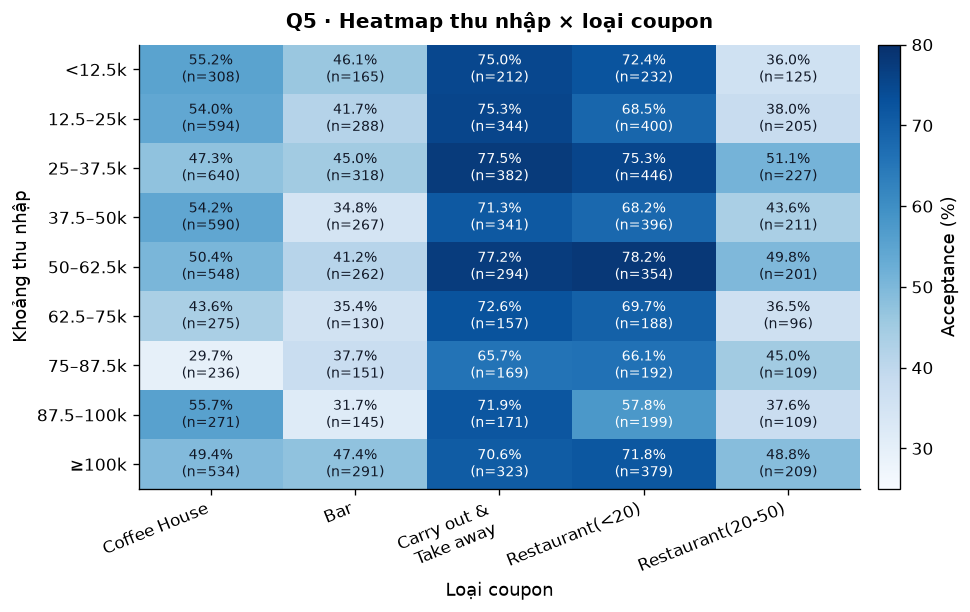

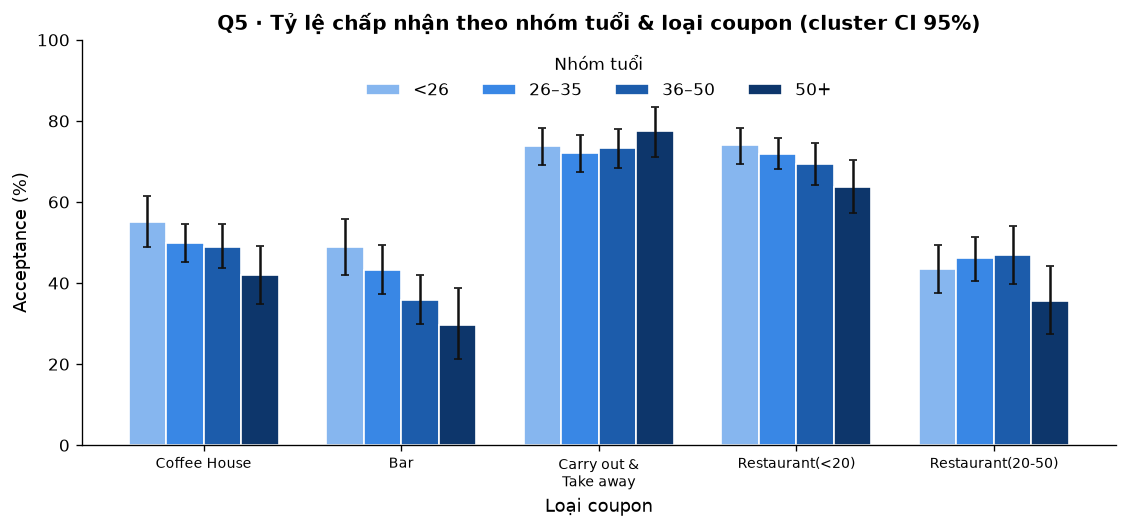

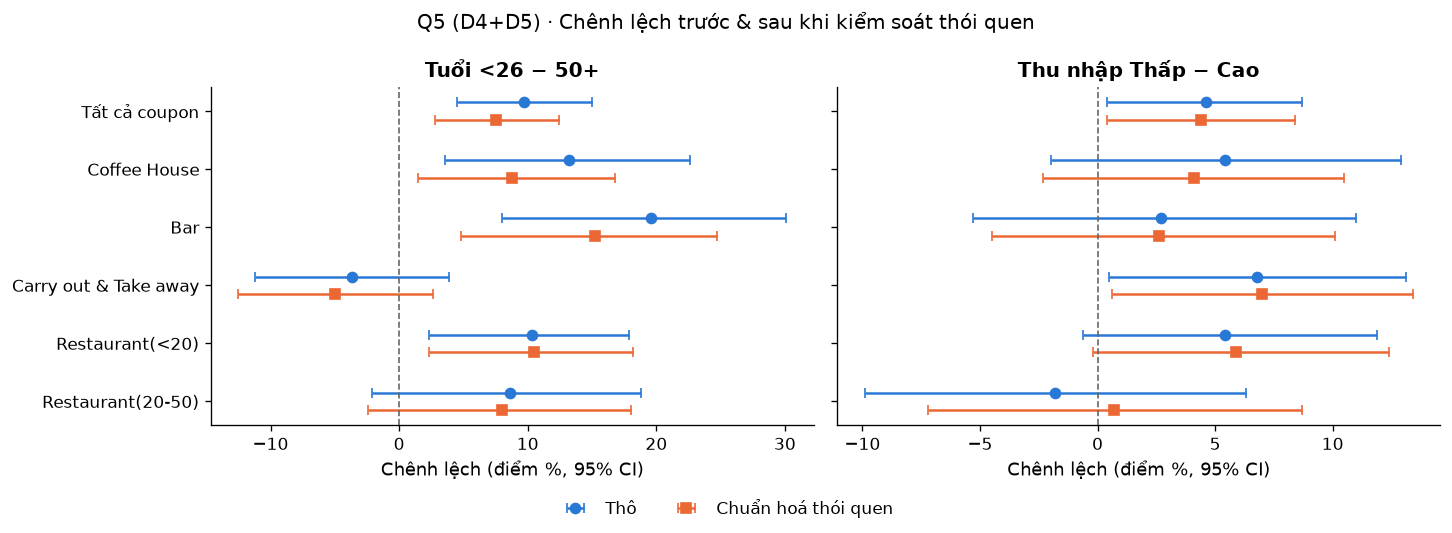

In [18]:
set_style()
coupon_ord_q5 = ["Coffee House", "Bar", "Carry out & Take away", "Restaurant(<20)",
                 "Restaurant(20-50)"]
coupon_labels = [c.replace(" & ", " &\n") for c in coupon_ord_q5]

# Hình 1: heatmap thu nhập × coupon (mỗi ô ghi tỷ lệ và n)
rate_ic = q5.pivot_table("Y", "income", "coupon", "mean", observed=True)[coupon_ord_q5].mul(100)
n_ic = q5.pivot_table("Y", "income", "coupon", "count", observed=True)[coupon_ord_q5]
rate_ic.index, rate_ic.columns = INCOME_SHORT, coupon_labels
n_ic.index, n_ic.columns = INCOME_SHORT, coupon_labels
plot_heatmap(rate_ic, n_ic, "Q5 · Heatmap thu nhập × loại coupon", "Loại coupon",
             "Khoảng thu nhập", out_name="q5_fig1_income_coupon_heatmap", cmap="Blues",
             vmin=25, vmax=80, figsize=(8.6, 5.2))
plt.show()

# Hình 2: tỷ lệ theo nhóm tuổi trong từng coupon, CI 95% theo người
age_ci = {c: cluster_rates_ci(q5[q5["coupon"] == c], "age_group") for c in coupon_ord_q5}
x, bw = np.arange(5), 0.19
age_cols = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
fig, ax = plt.subplots(figsize=(9.5, 4.5))
for k, ag in enumerate(AGE_GROUPS):
    r = np.array([age_ci[c].loc[ag, "rate_pct"] for c in coupon_ord_q5])
    lo = np.array([age_ci[c].loc[ag, "ci_low_pct"] for c in coupon_ord_q5])
    hi = np.array([age_ci[c].loc[ag, "ci_high_pct"] for c in coupon_ord_q5])
    pos = x + (k - 1.5) * bw
    ax.bar(pos, r, width=bw, color=age_cols[k], edgecolor="white", label=ag)
    ax.errorbar(pos, r, yerr=[r - lo, hi - r], fmt="none", ecolor="#111", capsize=2.5)
ax.set_xticks(x, coupon_labels, fontsize=8.5)
ax.set(ylim=(0, 100), xlabel="Loại coupon", ylabel="Acceptance (%)",
       title="Q5 · Tỷ lệ chấp nhận theo nhóm tuổi & loại coupon (cluster CI 95%)")
ax.legend(title="Nhóm tuổi", ncol=4, loc="upper center", frameon=False)
fig.tight_layout()
save_figure(fig, "q5_fig2_age_group_by_coupon")
plt.show()

# Hình 3: chênh lệch thô và sau khi kiểm soát thói quen, toàn mẫu và trong từng coupon
SERIES = [  # (nhãn chú giải, các mức dieu_chinh thuộc chuỗi này, màu, ký hiệu, độ lệch dọc)
    ("Thô", ["Thô"], "#2a78d6", "o", -0.15),
    ("Chuẩn hoá thói quen", ["Chuẩn hoá coupon × thói quen", "Chuẩn hoá thói quen"],
     "#eb6834", "s", 0.15),
]
scopes = ["Tất cả coupon"] + coupon_ord_q5
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4), sharey=True)
for ax, cname in zip(axes, ["Tuổi <26 − 50+", "Thu nhập Thấp − Cao"]):
    part = q5_contrasts[q5_contrasts["so_sanh"] == cname]
    for label, levels, color, marker, offset in SERIES:
        sel = part[part["dieu_chinh"].isin(levels)].set_index("pham_vi").loc[scopes]
        d = sel["diff_pp"].to_numpy()
        err = [d - sel["ci_low_pp"].to_numpy(), sel["ci_high_pp"].to_numpy() - d]
        ax.errorbar(d, np.arange(len(scopes)) + offset, xerr=err, fmt=marker, color=color,
                    capsize=3, label=label)
    ax.axvline(0, color="#666", linestyle="--", linewidth=1)
    ax.set(title=cname, xlabel="Chênh lệch (điểm %, 95% CI)")
axes[0].set_yticks(range(len(scopes)), scopes)
axes[0].invert_yaxis()
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Q5 (D4+D5) · Chênh lệch trước & sau khi kiểm soát thói quen")
fig.tight_layout(rect=(0, 0.06, 1, 1))
save_figure(fig, "q5_fig3_contrasts_raw_vs_adjusted")
plt.show()

#### Kết quả & kết luận Q5 *(CI 95% bootstrap theo người; so sánh có kiểm soát thói quen dùng `12.520` dòng của `560` người)*
1. **Trong cùng loại coupon, nhóm nào nhận nhiều/ít?** Tính thô trên toàn bộ dữ liệu, tỷ lệ giảm dần theo tuổi: `<26` **60,4%** (`3.200` dòng, `143` người, CI `[57,5; 63,3]`) → `50+` **50,9%** (`1.788` dòng, `84` người, CI `[46,5; 54,9]`). Trong từng coupon, chênh `<26 − 50+` lớn nhất ở `Bar` (**+19,6 pp**, CI `[8,0; 30,1]`), `Coffee House` (`+13,2 pp`) và `Restaurant(<20)` (`+10,3 pp`); `Restaurant(20-50)` chưa rõ (`+8,6 pp`, CI chứa 0) và `Carry out` hơi ngược chiều (`−3,7 pp`, CI `[−11,2; 3,9]`). Thu nhập không giảm theo đường thẳng: thấp nhất ở `75–87,5k` (**48,3%**, `38` người) nhưng `≥100k` lại **57,8%** (`73` người).
2. **Sau khi kiểm soát thói quen:** trên `12.520` dòng đủ thông tin thói quen, chênh lệch tuổi `<26 − 50+` giảm từ **+9,7 pp** (thô) còn **+7,5 pp** (CI `[2,8; 12,4]`), tức khoảng **23%** khác biệt đi cùng thói quen — người trẻ có thói quen ghé bar/quán cà phê nhiều hơn (tỷ lệ người đi bar `≥ 1 lần/tháng`: **35,9%** ở `<26` so với **23,2%** ở `50+`; quán cà phê 54,2% so với 46,3%; xu hướng đúng chiều nhưng không giảm đều theo tuổi). Phần còn lại vẫn rõ ở `Bar` (`+19,6` → `+15,2 pp`) và `Coffee House` (`+13,2` → `+8,8 pp`); riêng `Restaurant(<20)` gần như không đổi (`+10,3` → `+10,5 pp`). Thu nhập `Thấp − Cao` chỉ **+4,4 pp** (CI `[0,4; 8,4]`, sát 0) và khi giữ cố định nhóm tuổi còn `+3,8 pp` (CI `[−0,6; 7,8]`), không còn phân biệt được với 0.
3. **Ô nhỏ:** `9/40` ô `coupon × thói quen × tuổi` có `< 30` người (nhỏ nhất `10` người), nên CI trong từng coupon rộng (ví dụ `Bar` rộng ~22 pp). Ba khoảng thu nhập `62,5k–100k` chỉ có `38–40` người, CI rộng ~13–15 pp.
4. **Đổi cách gộp (D6):** chênh lệch tuổi luôn dương ở mọi phương án, nhưng chia đôi `<36 − 36+` chỉ còn `+3,2 pp` (CI `[−0,1; 6,5]`): khác biệt nằm chủ yếu ở hai đầu tuổi. Ngưỡng thói quen `≥4`/tháng cho kết quả tương tự (`+9,8 pp`) nhưng `45/2000` lần bootstrap có tầng rỗng vì ít người đạt ngưỡng. Thu nhập chia đôi `<50k − ≥50k` cũng chứa 0 (`+2,9 pp`) nên kết luận về thu nhập ổn định. Bootstrap theo dòng cho CI hẹp hơn ~1,8 lần (rộng `5,4` so với `9,6` pp): bỏ qua việc một người trả lời ~22 tình huống sẽ làm kết luận tự tin quá mức.

- **Điểm bất ngờ:** giả thuyết "thu nhập càng cao càng ít cần coupon" không đúng trong khảo sát: nhóm `≥100k` nhận gần bằng nhóm thấp nhất. `Carry out` là coupon duy nhất mà người `50+` nhận nhiều hơn người `<26`.
- **Ứng dụng có điều kiện:** khi phân khúc, loại coupon và thói quen hữu ích hơn thu nhập; tuổi chỉ đáng dùng thêm cho `Bar`/`Coffee House`. Chỉ áp dụng trong phạm vi khảo sát ý định này.
- **Hạn chế:** dữ liệu MTurk đo ý định giả định; `respondent_id` suy ra từ hồ sơ trùng nên có thể gộp nhầm vài người có hồ sơ giống hệt (một số "người" có 44, 66 hay 110 dòng — xem phân bố số dòng/người ở trên); thói quen chỉ được kiểm soát ở 2 mức nên vẫn có thể còn biến nhiễu khác; đây là mối liên hệ quan sát, không phải nhân quả.

---
## Phase 2.4 · Tổng hợp Q1–Q6, Hạn chế & Hướng phát triển

| Câu | Owner | Kết luận định lượng cốt lõi |
| --- | --- | --- |
| **Q1** | Dương | Gần (`5-<15 min`: **61,42%**) > xa (`>=25 min`: **42,89%**, **+18,53 pp**); `Restaurant(<20)` giảm **42,74 pp** còn `Carry out` gần như phẳng (**73,21%** ở `>=25 min`); đi cùng hướng trong `Home` cao hơn **+17,40 pp**. |
| **Q2** | Dương | `1d` (**62,56%**) > `2h` (**49,60%**, **+12,96 pp**); nghịch lý Simpson lúc `10AM` (gộp thô `−2,01 pp` nhưng 5/5 coupon đều `1d > 2h`); `Bar` gần như không phụ thuộc thời hạn (`+0,85 pp`, CI chứa 0). |
| **Q3** | Hà | Thường xuyên > ít ghé ở cả 5 coupon (ước lượng điểm): `Bar` (**+39,58 pp**), `Coffee House` (**+31,41 pp**), `Restaurant(20-50)` (**+17,15 pp**), `Carry out` (**+5,80 pp**), `Restaurant(<20)` (**+5,39 pp**); tính CI theo người thì chỉ 3 loại đầu còn rõ ràng. |
| **Q4** | Hà | Thô `Friend(s) − Alone` **+14,76 pp** thu hẹp còn **+1,33 pp** (CI `[−1,70; 4,51]`, `41,6%` support) sau chuẩn hóa `coupon × destination` do `Friend(s)` chỉ có ở `No Urgent Place`. |
| **Q5** | Lý | Tuổi `<26 − 50+` giảm từ `+9,7` xuống **+7,5 pp** (CI `[2,8; 12,4]`) sau chuẩn hóa thói quen; thu nhập `Thấp − Cao` mất ý nghĩa (**+3,8 pp**, CI chứa 0) khi cố định tuổi. |
| **Q6** | Lý | Random Forest (`03_ml_question.ipynb`) đạt test **ROC-AUC = 0,781** (CI `[0,755; 0,807]`), **balanced accuracy = 0,706**; dẫn dắt bởi `coupon`, `CoffeeHouse`, `expiration`, `Bar` (nhân khẩu học gần 0). |

### Kiểm tra lại kết luận chính bằng CI theo người (D5, D6)
Q1–Q4 tính CI bằng bootstrap theo **dòng**, tức coi `12.684` dòng là độc lập. Nhưng mỗi người trả lời khoảng 22 tình huống, và ở Q5 bootstrap theo người cho CI rộng hơn khoảng 1,8 lần. Bảng dưới tính lại CI 95% cho các chênh lệch chính của Q1–Q4 bằng **bootstrap theo người** (`cluster_diff_ci`, dùng `respondent_id` dựng ở Q5; Q3 dùng đúng định nghĩa chính: ngưỡng `≥ 1 lần/tháng`, complete-case) để xem kết luận nào vẫn đứng vững.

In [19]:
# respondent_id dựng ở Q5 có cùng chỉ số dòng với df -> gắn vào dữ liệu của Q1–Q4
base = df.assign(
    respondent_id=q5["respondent_id"],
    travel_time_band=q1_df["travel_time_band"],
    expiration=pd.Categorical(df["expiration"], EXPIRATION_ORDER, ordered=True),
    direction=pd.Categorical(df["direction_same"].map({0: "ngược", 1: "cùng"}),
                             ["ngược", "cùng"], ordered=True),
    passenger=pd.Categorical(df["passanger"], PASSENGERS, ordered=True),
)
CHECKS = [  # (kết luận cần kiểm, dữ liệu, cột nhóm, nhóm A, nhóm B)
    ("Q1 · gần − xa (toàn mẫu)", base, "travel_time_band", NEAR, FAR),
    ("Q1 · cùng − ngược hướng (Home)", base[base["destination"] == "Home"],
     "direction", "cùng", "ngược"),
    ("Q2 · 1d − 2h (toàn mẫu)", base, "expiration", "1d", "2h"),
    ("Q4 · Friend(s) − Alone (thô)", base, "passenger", "Friend(s)", "Alone"),
    ("Q4 · Partner − Alone (thô)", base, "passenger", "Partner", "Alone"),
]
check_rows = [{"ket_luan": name, **cluster_diff_ci(data, col, a, b)}
              for name, data, col, a, b in CHECKS]
for coupon in COUPONS:  # Q3: thường − ít ghé trong từng coupon
    in_coupon = q5_cc[q5_cc["coupon"] == coupon]
    check_rows.append({"ket_luan": f"Q3 · thường − ít ghé ({coupon})",
                       **cluster_diff_ci(in_coupon, "frequent_user", "Thường (≥1)", "Ít (<1)")})
cluster_check = pd.DataFrame(check_rows)
cluster_check["ci_chua_0"] = (cluster_check["ci_low_pp"] <= 0) & (cluster_check["ci_high_pp"] >= 0)
save_table(cluster_check, "summary_cluster_ci_check")
display(cluster_check.drop(columns="empty_strata_draws"))

,ket_luan,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,ci_chua_0
0,Q1 · gần − xa (toàn mẫu),61.4,42.9,18.5,15.4,21.5,False
1,Q1 · cùng − ngược hướng (Home),59.8,42.4,17.4,14.3,20.7,False
2,Q2 · 1d − 2h (toàn mẫu),62.6,49.6,13.0,10.8,15.2,False
3,Q4 · Friend(s) − Alone (thô),67.3,52.6,14.8,12.5,17.1,False
4,Q4 · Partner − Alone (thô),59.5,52.6,7.0,3.3,10.6,False
5,Q3 · thường − ít ghé (Bar),68.8,29.2,39.6,33.3,45.6,False
6,Q3 · thường − ít ghé (Coffee House),66.0,34.6,31.4,26.4,36.5,False
7,Q3 · thường − ít ghé (Carry out & Take away),74.4,68.6,5.8,-0.9,12.7,True
8,Q3 · thường − ít ghé (Restaurant(<20)),71.5,66.1,5.4,-1.2,11.7,True
9,Q3 · thường − ít ghé (Restaurant(20-50)),55.5,38.4,17.2,10.7,23.7,False


→ Kết luận của **Q1, Q2 và Q4 (thô) vẫn đứng vững**: CI theo người chỉ rộng hơn CI theo dòng một chút (ví dụ Q1 gần − xa: `[15,4; 21,5]` so với `[15,69; 21,38]`), vì mỗi người đều trả lời cả hai điều kiện được so sánh (gần/xa, `1d`/`2h`, đi một mình/đi cùng người khác) — phép so sánh diễn ra *bên trong* từng người. Ngược lại, ở **Q3** thói quen là đặc điểm cố định của mỗi người (so sánh *giữa* các người) nên CI rộng ra rõ: `Bar`, `Coffee House`, `Restaurant(20-50)` vẫn rõ ràng, còn `Carry out & Take away` (`[−0,9; 12,7]`) và `Restaurant(<20)` (`[−1,2; 11,7]`) **chứa 0** → với hai loại coupon này chưa đủ bằng chứng để nói thói quen đi kèm tỷ lệ nhận cao hơn. Đây cũng là lý do Q5 (tuổi, thu nhập — đặc điểm của người) dùng bootstrap theo người ngay từ đầu.

### Các phát hiện chính (Key findings)
1. **Loại coupon & thói quen áp đảo nhân khẩu học** (thống nhất giữa Q3, Q5 và permutation importance ở Q6).
2. **Phân tích gộp thô dễ đánh lừa do cấu trúc khảo sát** (nghịch lý Simpson lúc `10AM` ở Q2, `destination` che khuất `direction_same` ở Q1, `Friend(s)` chỉ có ở `No Urgent Place` ở Q4).
3. **Độ nhạy với khoảng cách và thời hạn phụ thuộc mạnh vào loại dịch vụ** (`Carry out` ít nhạy khoảng cách; `Bar` gần như không phụ thuộc thời hạn).
4. **Một người trả lời nhiều tình huống (`567` người suy ra)** ảnh hưởng trực tiếp tới độ rộng CI (Q5, bảng kiểm tra theo người ở trên) và tới cách chia dữ liệu ở Q6 (nếu chia fold CV theo dòng thay vì theo người, ROC-AUC CV bị thổi phồng `+0,043`).

> **Phát hiện bất ngờ nhất — nghịch lý Simpson lúc `10AM` (Q2) & thu nhập không tuyến tính (Q5):** lúc `10AM`, gộp thô cho cảm giác coupon `2h` tốt hơn `1d` (`−2,01 pp`), nhưng tách riêng từng loại coupon thì **cả 5/5 loại đều có ước lượng `1d > 2h`** (`+2,41` đến `+23,02 pp`) do lệch cơ cấu loại coupon. Ở Q5, nhóm thu nhập cao nhất `≥100k USD` vẫn chấp nhận **57,8%** — không thấp hơn trung bình mẫu `56,84%` (CI `[53,6; 62,1]` chứa mức trung bình), trái với giả định "thu nhập càng cao càng ít quan tâm ưu đãi".

### Hạn chế chung (Limitations)
- **Dữ liệu:** khảo sát MTurk đo **ý định giả định**, không phải hành vi đổi coupon thực tế; tần suất ghé quán là tự khai báo; cột `car` thiếu `99,15%` nên không dùng làm biến phân tích (chỉ dùng trong khóa suy ra `respondent_id`).
- **Phương pháp:** bộ dữ liệu không có mã người trả lời nên `respondent_id` (`567` người) chỉ là xấp xỉ từ hồ sơ trùng; CI chính ở Q1–Q4 giả định các dòng độc lập nên hẹp hơn thực tế (bảng kiểm tra theo người ở trên cho thấy mức độ và kết luận nào bị ảnh hưởng); chưa hiệu chỉnh cho việc so sánh nhiều lần (multiple comparisons).
- **Phạm vi:** có các ô rỗng do thiết kế kịch bản (`Friend(s)` chỉ ở `No Urgent Place`; `7AM` = 100% `Work`); mọi kết quả chỉ phản ánh **mối liên hệ quan sát**, không suy diễn nhân quả.

### Nếu có thêm thời gian, nhóm sẽ làm gì? (Future work)
- **Dữ liệu & thực nghiệm:** thử nghiệm A/B trực tiếp trên ứng dụng dẫn đường với lịch sử đổi coupon thật và mã người dùng rõ ràng để đo tỷ lệ chuyển đổi thực tế.
- **Phương pháp thống kê:** mở rộng bootstrap theo người sang toàn bộ Q1–Q4 và dùng mô hình hồi quy logistic nhiều biến để kiểm soát đồng thời nhiều biến nhiễu.
- **Machine Learning:** hiệu chỉnh xác suất dự đoán (calibration), chọn ngưỡng quyết định theo chi phí thực tế giữa làm phiền người dùng (`FP`) và bỏ lỡ cơ hội (`FN`), thử thêm Gradient Boosting và xử lý người dùng mới chưa có lịch sử thói quen (*cold-start*).
- **Câu hỏi mở rộng:** tương tác giữa thời tiết/nhiệt độ với bán kính di chuyển chấp nhận được cho từng nhóm dịch vụ ăn uống.

## Reflection
> Theo đề: **mỗi thành viên** tự trả lời *"Bạn đã gặp những khó khăn gì?"* và *"Bạn đã học được gì?"*; **cả nhóm** trả lời *"Nếu có thêm thời gian, nhóm sẽ làm gì?"* (mục ngay phía trên). Phần của từng người do chính người đó tự viết.

**Trần Nhật Dương (23120243)**
- *Khó khăn đã gặp:* (tự viết)
- *Điều đã học được:* (tự viết)

**Nguyễn Mạnh Hà (23120248)**
- *Khó khăn đã gặp:* (tự viết)
- *Điều đã học được:* (tự viết)

**Hoàng Công Lý (24120378)**
- *Khó khăn đã gặp:* (tự viết)
- *Điều đã học được:* (tự viết)

## Tài liệu tham khảo (References)
1. UCI Machine Learning Repository — *In-Vehicle Coupon Recommendation* (Dataset #603). DOI `10.24432/C5GS4P`, giấy phép CC BY 4.0. <https://archive.ics.uci.edu/dataset/603/in+vehicle+coupon+recommendation>
2. Wang, T., Rudin, C., Doshi-Velez, F., Liu, Y., Klampfl, E., & MacNeille, P. (2017). A Bayesian Framework for Learning Rule Sets for Interpretable Classification. *Journal of Machine Learning Research*, 18(70), 1–37.
3. Phân tích công khai trên cùng dữ liệu (dùng để đối chiếu, không sao chép code): `seetharamanr86/customer_coupon_acceptance`, `arnavkundu/MLEngineerNanoDegree-Capstone` (GitHub) — chi tiết ở `docs/related_work.md`.
4. Tài liệu thư viện: pandas User Guide (`groupby`, `pivot_table`, `melt`, `Categorical`, `crosstab`); NumPy (`numpy.random.Generator`); Matplotlib; scikit-learn User Guide (`Pipeline`, `ColumnTransformer`, `SimpleImputer`, `OneHotEncoder`, `GroupShuffleSplit`, `StratifiedGroupKFold`, `GridSearchCV`, các metric phân loại, `permutation_importance`).
5. Phương pháp thống kê: Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *JASA*, 22(158), 209–212 · Efron, B., & Tibshirani, R. (1993). *An Introduction to the Bootstrap*. Chapman & Hall · Field, C. A., & Welsh, A. H. (2007). Bootstrapping clustered data. *JRSS B*, 69(3), 369–390 · Simpson, E. H. (1951). The interpretation of interaction in contingency tables. *JRSS B*, 13(2), 238–241.
6. Slide bài giảng và hướng dẫn Final Project môn CSC17104 (Khoa CNTT, ĐH KHTN – ĐHQG TP.HCM).
7. Công cụ AI được dùng như gia sư và để rà soát (chi tiết từng lần dùng trong `LLM_USAGE.md`).